# Análisis Exploratorio de Datos (EDA)
## Evolución de la demanda educativa en la Provincia de Buenos Aires
**- Chiara Camila Romano**

El presente notebook desarrolla el Análisis Exploratorio de Datos (EDA) del conjunto de datos construido para estudiar la evolución de la demanda educativa en los 135 partidos de la Provincia de Buenos Aires.

El dataset integra información proveniente de distintas fuentes oficiales y reúne variables educativas, demográficas, socioeconómicas, habitacionales y migratorias.

La unidad de análisis es el **partido-año**. El período estructural del dataset comprende los años **2012 a 2035**, aunque la cobertura temporal varía según la fuente. En particular, la matrícula educativa observada se encuentra disponible hasta 2025, mientras que los años posteriores forman parte del horizonte futuro considerado para el proyecto.

El objetivo de este EDA es conocer la estructura y calidad de los datos, analizar sus distribuciones y relaciones, identificar valores faltantes y posibles anomalías, y obtener los primeros hallazgos que servirán como base para la posterior etapa de modelado.

# 1. Presentación del conjunto de datos
### 1.1 Librerías y carga

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

df = pd.read_csv("../01_datos/dataset_maestro_final.csv")

print("Dataset cargado correctamente.")

Dataset cargado correctamente.


### 1.2 Estructura general del dataset

En primer lugar se analiza la estructura general del conjunto de datos: cantidad de registros y variables, número de partidos representados, período disponible y existencia de duplicados en la clave partido-año.

In [7]:
print("Dimensiones del dataset:", df.shape)
print("Cantidad de partidos:", df["partido"].nunique())
print("Año mínimo:", df["anio"].min())
print("Año máximo:", df["anio"].max())
print("Cantidad de años:", df["anio"].nunique())

duplicados = df.duplicated(
    subset=["partido", "anio"]
).sum()

print("Duplicados partido-año:", duplicados)

Dimensiones del dataset: (3240, 62)
Cantidad de partidos: 135
Año mínimo: 2012
Año máximo: 2035
Cantidad de años: 24
Duplicados partido-año: 0


El dataset final contiene **3.240 registros y 62 variables**, correspondientes a los **135 partidos de la Provincia de Buenos Aires** durante un período estructural de **24 años (2012-2035)**.

Cada registro representa la combinación de un partido y un año. La estructura esperada se cumple exactamente:

**135 partidos × 24 años = 3.240 registros.**

Además, no se detectaron registros duplicados para la combinación `partido-año`, por lo que esta puede utilizarse como clave de identificación del dataset.

### 1.3 Vista inicial de los datos

A continuación se presentan las primeras filas del dataset para observar su estructura y el formato general de las variables.

In [8]:
df.head()

,partido,anio,nacimientos,poblacion_total,tbn,matricula_inicial,matricula_primaria,matricula_secundaria,matricula_total,poblacion_estimada,...,porcentaje_residia_fuera_localidad_2017,poblacion_2010,poblacion_2022,variacion_absoluta,variacion_relativa,superficie_km2,densidad_2022,poblacion_0_5,poblacion_6_11,poblacion_12_17
0,25 DE MAYO,2012,575.0,36343.0,15.82,2005.0,3663.0,3133.0,8801.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,25 DE MAYO,2013,519.0,36439.0,14.24,2049.0,3627.0,3157.0,8833.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,25 DE MAYO,2014,526.0,36533.0,14.40,2143.0,3595.0,3200.0,8938.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,25 DE MAYO,2015,550.0,36627.0,15.02,2093.0,3530.0,3282.0,8905.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,25 DE MAYO,2016,493.0,36718.0,13.43,2096.0,3543.0,3245.0,8884.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1.4 Cobertura temporal de las principales fuentes

Aunque la estructura general comprende el período 2012-2035, las variables provienen de distintas fuentes y no todas poseen la misma cobertura temporal.

Por este motivo, es importante diferenciar entre series históricas, variables estructurales correspondientes a un año específico y estimaciones futuras.

In [9]:
variables_clave = [
    "matricula_total",
    "nacimientos",
    "poblacion_total",
    "poblacion_estimada"
]

for variable in variables_clave:
    datos_disponibles = df[df[variable].notna()]

    print(
        f"{variable}: "
        f"{datos_disponibles['anio'].min()} - "
        f"{datos_disponibles['anio'].max()}"
    )

matricula_total: 2012 - 2025
nacimientos: 2012 - 2022
poblacion_total: 2012 - 2022
poblacion_estimada: 2022 - 2035


La cobertura temporal depende de la fuente utilizada. La matrícula educativa constituye la principal serie histórica de interés y se encuentra disponible entre **2012 y 2025**. Los nacimientos y la población histórica poseen información hasta **2022**, mientras que las estimaciones de población permiten extender el análisis demográfico hasta **2035**.

Además, varias variables censales, socioeconómicas y habitacionales corresponden específicamente al **Censo 2022**, por lo que deben interpretarse como características estructurales de los partidos y no como series temporales anuales.

Esta diferencia de cobertura será considerada tanto durante el EDA como en la posterior selección de variables para el modelado.

## 2. Descripción de variables

El dataset integra variables provenientes de distintas dimensiones relacionadas con la demanda educativa. Para facilitar su interpretación, las variables pueden organizarse en los siguientes grupos temáticos.

### 2.1 Variables de identificación

Permiten identificar la unidad de análisis:

- `partido`: partido de la Provincia de Buenos Aires.
- `anio`: año de referencia.

### 2.2 Variables educativas

Incluyen información sobre matrícula y asistencia educativa, entre ellas:

- matrícula de nivel Inicial;
- matrícula de nivel Primario;
- matrícula de nivel Secundario;
- matrícula total;
- población que asiste a establecimientos educativos según el Censo 2022;
- asistencia por nivel educativo;
- tasa de asistencia censal;
- población que nunca asistió.

La **matrícula** constituye la variable principal para representar la demanda educativa.

### 2.3 Variables demográficas

Describen el tamaño y la composición de la población de cada partido:

- población total;
- población estimada;
- población por grupos de edad;
- población de 0 a 5 años;
- población de 6 a 11 años;
- población de 12 a 17 años;
- densidad poblacional;
- superficie;
- variación de población.

### 2.4 Variables de natalidad y fecundidad

Incluyen indicadores relacionados con la dinámica demográfica:

- cantidad de nacimientos;
- tasa bruta de natalidad;
- cantidad de mujeres;
- cantidad de mujeres con hijos;
- cantidad de hijos;
- promedio de hijos por mujer.

### 2.5 Variables socioeconómicas

Caracterizan la situación económica de la población:

- tasa de actividad;
- tasa de empleo;
- tasa de desocupación;
- población económicamente activa;
- población ocupada;
- población desocupada.

### 2.6 Variables habitacionales

Describen algunas características de los hogares:

- acceso a agua de red;
- acceso a cloacas;
- hogares sin baño;
- cantidad total de hogares.

### 2.7 Variables migratorias

Incluyen información relacionada con el lugar de residencia previo de la población y permiten aproximar la movilidad territorial entre partidos.

### 2.8 Tipos de datos

Se revisan los tipos de datos utilizados para verificar que las variables se encuentren representadas de forma adecuada para el análisis.

In [10]:
df.dtypes.value_counts()

,count
float64,60
object,1
int64,1


In [11]:
df[["partido", "anio"]].dtypes

,0
partido,object
anio,int64


## 3. Análisis de valores faltantes

El análisis de valores faltantes permite determinar si la ausencia de información corresponde a problemas de calidad de los datos o a diferencias en la cobertura temporal de las fuentes utilizadas.

Dado que el dataset integra información educativa, demográfica, censal, socioeconómica y habitacional proveniente de distintas fuentes, no todas las variables poseen datos para todos los años del período 2012-2035.

 ### 3.1 Cantidad y porcentaje de valores faltantes por variable

In [12]:
faltantes = pd.DataFrame({
    "cantidad_faltantes": df.isna().sum(),
    "porcentaje_faltantes": (df.isna().mean() * 100).round(2)
})

faltantes = (
    faltantes[faltantes["cantidad_faltantes"] > 0]
    .sort_values("porcentaje_faltantes", ascending=False)
)

faltantes

,cantidad_faltantes,porcentaje_faltantes
variacion_relativa,3106,95.86
poblacion_2010,3106,95.86
variacion_absoluta,3106,95.86
poblacion_educacion_censo,3105,95.83
asiste_universitario_censo_2022,3105,95.83
asiste_terciario_censo_2022,3105,95.83
asiste_secundario_censo_2022,3105,95.83
asiste_primario_censo_2022,3105,95.83
asiste_sala_4_5_censo_2022,3105,95.83
asiste_censo_2022,3105,95.83


Se observa que varias variables presentan porcentajes elevados de valores faltantes. Sin embargo, esto no implica necesariamente problemas de calidad.

La principal explicación es la diferente cobertura temporal de las fuentes. Por ejemplo, diversas variables censales y socioeconómicas corresponden exclusivamente al año 2022, mientras que la estructura del dataset contiene una fila para cada combinación partido-año entre 2012 y 2035.

Por lo tanto, un valor `NaN` puede representar simplemente que una determinada variable no fue medida para ese año.

### 3.2 Cobertura temporal de las variables

Para distinguir los faltantes estructurales de posibles problemas de calidad, se analiza el período en el que cada variable presenta información disponible.

In [13]:
cobertura_temporal = []

for variable in df.columns:

    if variable not in ["partido", "anio"]:

        datos = df[df[variable].notna()]

        if len(datos) > 0:
            cobertura_temporal.append({
                "variable": variable,
                "anio_min": datos["anio"].min(),
                "anio_max": datos["anio"].max(),
                "cantidad_anios": datos["anio"].nunique(),
                "cantidad_datos": datos[variable].notna().sum()
            })

cobertura_temporal = pd.DataFrame(cobertura_temporal)

cobertura_temporal

,variable,anio_min,anio_max,cantidad_anios,cantidad_datos
0,nacimientos,2012,2022,11,1485
1,poblacion_total,2012,2022,11,1485
2,tbn,2012,2022,11,1485
3,matricula_inicial,2012,2025,14,1890
4,matricula_primaria,2012,2025,14,1890
5,matricula_secundaria,2012,2025,14,1878
6,matricula_total,2012,2025,14,1878
7,poblacion_estimada,2022,2035,14,1890
8,poblacion_educacion_censo,2022,2022,1,135
9,asiste_censo_2022,2022,2022,1,135


#### Interpretación

El elevado porcentaje de valores faltantes observado en varias variables se explica principalmente por las diferencias de cobertura temporal entre las fuentes y no por una pérdida generalizada de información.

Se identifican tres tipos principales de cobertura:

- **Series históricas:** la matrícula se encuentra disponible entre 2012 y 2025, mientras que los nacimientos, la población histórica y la tasa bruta de natalidad poseen información entre 2012 y 2022.
- **Estimaciones futuras:** la población estimada se encuentra disponible entre 2022 y 2035.
- **Variables estructurales:** gran parte de las variables educativas censales, socioeconómicas, habitacionales, migratorias y demográficas corresponden exclusivamente al año 2022. Por esta razón presentan aproximadamente un 95,83% de valores `NaN` al incorporarse a un dataset cuya estructura comprende 24 años.

Por lo tanto, estos valores faltantes deben interpretarse considerando la fuente y el período de referencia de cada variable. No sería metodológicamente correcto completar automáticamente los años en los que la fuente original no proporciona información.

### 3.3 Valores faltantes en la matrícula

Debido a que la matrícula constituye la principal variable de interés del proyecto, se analiza por separado su disponibilidad durante el período histórico observado (2012-2025).

Los años 2026-2035 no se consideran faltantes problemáticos de matrícula, ya que corresponden al horizonte futuro para el cual posteriormente se buscará realizar estimaciones.

In [14]:
matricula_historica = df[
    (df["anio"] >= 2012) &
    (df["anio"] <= 2025)
].copy()

columnas_matricula = [
    "matricula_inicial",
    "matricula_primaria",
    "matricula_secundaria",
    "matricula_total"
]

faltantes_matricula = pd.DataFrame({
    "cantidad_faltantes": matricula_historica[columnas_matricula].isna().sum(),
    "porcentaje_faltantes": (
        matricula_historica[columnas_matricula].isna().mean() * 100
    ).round(2)
})

faltantes_matricula

,cantidad_faltantes,porcentaje_faltantes
matricula_inicial,0,0.00
matricula_primaria,0,0.00
matricula_secundaria,12,0.63
matricula_total,12,0.63


### 3.4 Registros históricos con algún faltante de matrícula


In [15]:
registros_faltantes_matricula = matricula_historica[
    matricula_historica[columnas_matricula].isna().any(axis=1)
][
    ["partido", "anio"] + columnas_matricula
]

registros_faltantes_matricula

,partido,anio,matricula_inicial,matricula_primaria,matricula_secundaria,matricula_total
600,CASTELLI,2012,40.0,160.0,NaN,NaN
601,CASTELLI,2013,40.0,140.0,NaN,NaN
602,CASTELLI,2014,33.0,131.0,NaN,NaN
603,CASTELLI,2015,36.0,152.0,NaN,NaN
604,CASTELLI,2016,45.0,150.0,NaN,NaN
1731,LEZAMA,2015,11.0,37.0,NaN,NaN
1732,LEZAMA,2016,14.0,33.0,NaN,NaN
1733,LEZAMA,2017,11.0,35.0,NaN,NaN
1734,LEZAMA,2018,14.0,38.0,NaN,NaN
1735,LEZAMA,2019,11.0,32.0,NaN,NaN


#### Interpretación de los faltantes históricos de matrícula

Durante el período histórico 2012-2025, las variables de matrícula Inicial y Primaria no presentan valores faltantes.

En matrícula Secundaria se identificaron **12 registros faltantes (0,63%)**, que también generan 12 valores faltantes en la matrícula total, ya que esta última se construye a partir de la suma de los tres niveles educativos.

Los casos se concentran exclusivamente en dos partidos:

- **Castelli:** matrícula Secundaria faltante entre 2012 y 2016.
- **Lezama:** matrícula Secundaria faltante entre 2015 y 2021.

Estos casos representan situaciones específicas de cobertura histórica y no un problema generalizado de la serie de matrícula.

Además, los valores faltantes de matrícula correspondientes al período 2026-2035 no se consideran datos perdidos, ya que representan el horizonte futuro para el cual posteriormente se buscará estimar la demanda educativa.

In [16]:
# Identificación del partido con faltantes en variables de variación poblacional

df_2022 = df[df["anio"] == 2022]

df_2022[
    df_2022[
        ["poblacion_2010", "variacion_absoluta", "variacion_relativa"]
    ].isna().any(axis=1)
][
    ["partido", "poblacion_2010", "poblacion_2022",
     "variacion_absoluta", "variacion_relativa"]
]

,partido,poblacion_2010,poblacion_2022,variacion_absoluta,variacion_relativa
1738,LEZAMA,NaN,6221.0,NaN,NaN


### 3.5 Decisiones sobre los valores faltantes

Los valores faltantes no fueron imputados de manera automática.

Se distinguieron dos situaciones principales:

1. **Faltantes estructurales:** corresponden a variables cuya fuente solo proporciona información para determinados años. Estos valores se conservan como `NaN`, ya que completar artificialmente los años sin información introduciría datos no observados.

2. **Faltantes históricos específicos:** corresponden a registros particulares de determinadas series. Estos casos fueron revisados individualmente y se mantienen identificados para ser considerados en las etapas posteriores del análisis y modelado.

En particular, los valores de matrícula correspondientes a 2026-2035 no representan datos perdidos, sino el período futuro sobre el cual se pretende realizar posteriormente la estimación de la demanda educativa.

Este criterio permite conservar la información original disponible y evitar imputaciones sin fundamento metodológico.

#### Faltante en variables de variación poblacional

También se identificó un caso particular en el partido de **Lezama**, que no presenta información de población para 2010. Como consecuencia, tampoco pueden calcularse las variables de variación absoluta y variación relativa de la población entre 2010 y 2022.

Este caso se conserva como valor faltante y no se realiza una imputación, ya que no se dispone de información de origen suficiente para calcular estos indicadores de manera consistente.

## 4. Análisis de outliers

Se analizaron posibles valores extremos con el objetivo de distinguir entre observaciones atípicas que representan características reales de los partidos y posibles anomalías en las series históricas.

Dado que los partidos de la Provincia de Buenos Aires presentan grandes diferencias en población, matrícula, cantidad de nacimientos y densidad, la presencia de valores extremos no implica necesariamente errores en los datos.

### 4.1 Detección de valores extremos mediante IQR

Como primera aproximación se utilizó el método del rango intercuartílico (IQR). Se considera un valor extremo aquel que se encuentra por debajo de:

**Q1 - 1,5 × IQR**

o por encima de:

**Q3 + 1,5 × IQR**

El análisis se realiza sobre variables relevantes del año 2022, de manera de comparar los 135 partidos en un mismo período.

In [19]:
# Selección de datos correspondientes a 2022
df_2022 = df[df["anio"] == 2022].copy()

variables_outliers = [
    "matricula_total",
    "poblacion_total",
    "poblacion_estimada",
    "nacimientos",
    "densidad_2022",
    "tasa_actividad",
    "tasa_empleo",
    "tasa_desocupacion",
    "porcentaje_hogares_agua_red",
    "porcentaje_hogares_cloaca",
    "porcentaje_hogares_sin_banio"
]

resultados_outliers = []

for variable in variables_outliers:

    datos = df_2022[variable].dropna()

    q1 = datos.quantile(0.25)
    q3 = datos.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    cantidad_outliers = (
        (datos < limite_inferior) |
        (datos > limite_superior)
    ).sum()

    resultados_outliers.append({
        "variable": variable,
        "cantidad_outliers": cantidad_outliers,
        "porcentaje_outliers": round(
            cantidad_outliers / len(datos) * 100, 2
        ),
        "limite_inferior": round(limite_inferior, 2),
        "limite_superior": round(limite_superior, 2)
    })

resumen_outliers = pd.DataFrame(resultados_outliers)

resumen_outliers

,variable,cantidad_outliers,porcentaje_outliers,limite_inferior,limite_superior
0,matricula_total,22,16.30,-35779.00,68921.00
1,poblacion_total,23,17.04,-134054.00,268710.00
2,poblacion_estimada,24,17.78,-136521.75,273496.25
3,nacimientos,21,15.56,-1371.75,2714.25
4,densidad_2022,29,21.48,-339.19,583.34
5,tasa_actividad,2,1.48,59.11,70.33
6,tasa_empleo,3,2.22,53.34,66.46
7,tasa_desocupacion,0,0.00,0.03,14.65
8,porcentaje_hogares_agua_red,12,8.89,41.52,120.70
9,porcentaje_hogares_cloaca,0,0.00,3.41,119.58


### 4.2 Distribución de variables principales

Para visualizar la presencia de valores extremos se analizan tres variables relacionadas con el tamaño y la estructura territorial de los partidos: matrícula total, población total y densidad poblacional.

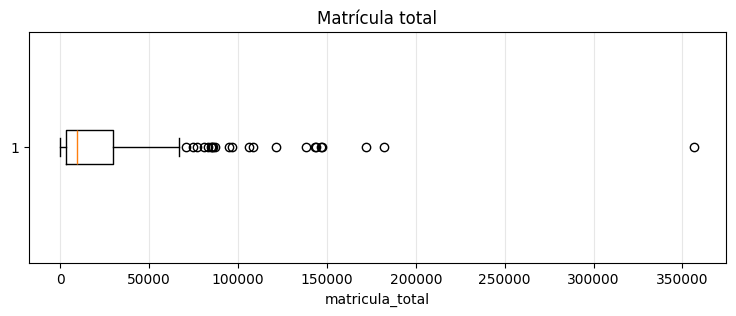

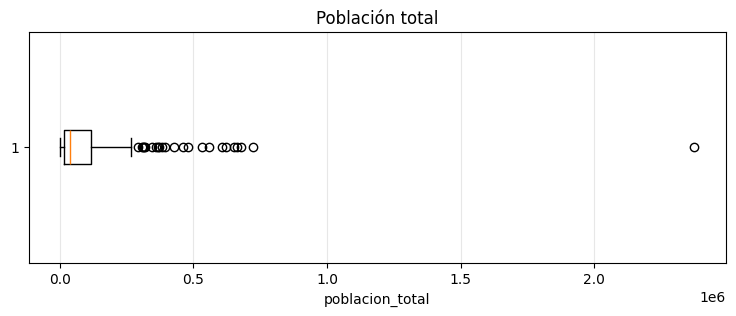

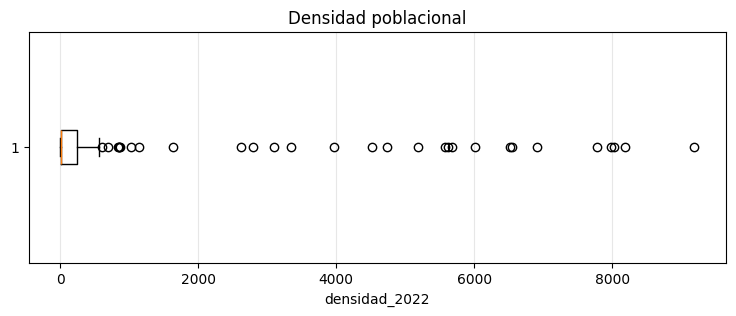

In [20]:
# Boxplots de variables principales

variables_boxplot = [
    ("matricula_total", "Matrícula total"),
    ("poblacion_total", "Población total"),
    ("densidad_2022", "Densidad poblacional")
]

for variable, titulo in variables_boxplot:

    plt.figure(figsize=(9, 3))

    plt.boxplot(
        df_2022[variable].dropna(),
        vert=False
    )

    plt.title(titulo)
    plt.xlabel(variable)

    plt.grid(axis="x", alpha=0.3)
    plt.show()

### 4.3 Interpretación de los valores extremos

El método IQR identifica una cantidad importante de valores extremos principalmente en variables absolutas como matrícula, población y nacimientos, y también en la densidad poblacional.

Sin embargo, estos valores no se consideran automáticamente errores. La Provincia de Buenos Aires presenta una marcada heterogeneidad territorial: algunos partidos concentran poblaciones y matrículas muy superiores al resto, mientras que otros poseen una población considerablemente menor.

En particular, partidos de gran tamaño poblacional como La Matanza, La Plata, Lomas de Zamora, Quilmes, Moreno y Merlo aparecen entre los valores superiores de matrícula y población. De manera similar, varios partidos altamente urbanizados presentan densidades considerablemente superiores al resto.

Por este motivo, estos valores extremos se conservan en el dataset, ya que representan diferencias territoriales reales que son relevantes para el problema de estimación de la demanda educativa.

### 4.4 Detección de anomalías en las series históricas

Además de los valores extremos entre partidos, se analizaron cambios interanuales de matrícula para identificar posibles discontinuidades dentro de las series históricas.

Este análisis permite diferenciar un partido naturalmente grande o pequeño de una observación que presenta un cambio abrupto respecto de sus propios valores históricos.

In [21]:
# Matrícula histórica 2012-2025

matricula_temporal = df[
    (df["anio"] >= 2012) &
    (df["anio"] <= 2025)
][
    ["partido", "anio", "matricula_total"]
].copy()

matricula_temporal = matricula_temporal.sort_values(
    ["partido", "anio"]
)

# Variación porcentual interanual
matricula_temporal["variacion_interanual"] = (
    matricula_temporal
    .groupby("partido")["matricula_total"]
    .pct_change(fill_method=None) * 100
)

# Mayores cambios absolutos
cambios_extremos = (
    matricula_temporal
    .dropna(subset=["variacion_interanual"])
    .assign(
        cambio_absoluto=lambda x:
        x["variacion_interanual"].abs()
    )
    .sort_values(
        "cambio_absoluto",
        ascending=False
    )
    .head(15)
)

cambios_extremos[
    [
        "partido",
        "anio",
        "matricula_total",
        "variacion_interanual"
    ]
].round(2)

,partido,anio,matricula_total,variacion_interanual
1730,LEZAMA,2014,972.0,1288.57
2434,PUNTA INDIO,2022,2834.0,276.36
2427,PUNTA INDIO,2015,795.0,-68.11
534,CARLOS CASARES,2018,4995.0,35.07
1232,GENERAL LAVALLE,2020,1421.0,32.06
533,CARLOS CASARES,2017,3698.0,-25.52
315,BENITO JUAREZ,2015,5229.0,25.31
99,ALBERTI,2015,2109.0,22.83
1234,GENERAL LAVALLE,2022,1528.0,22.83
1158,GENERAL JUAN MADARIAGA,2018,6286.0,21.30


### 4.5 Revisión de anomalías identificadas

In [22]:
partidos_revision = [
    "CASTELLI",
    "LEZAMA",
    "PUNTA INDIO",
    "CARLOS CASARES"
]

revision_anomalias = df[
    (df["partido"].isin(partidos_revision)) &
    (df["anio"].between(2012, 2025))
][
    [
        "partido",
        "anio",
        "matricula_inicial",
        "matricula_primaria",
        "matricula_secundaria",
        "matricula_total"
    ]
].sort_values(
    ["partido", "anio"]
)

revision_anomalias

,partido,anio,matricula_inicial,matricula_primaria,matricula_secundaria,matricula_total
528,CARLOS CASARES,2012,1131.0,2050.0,1778.0,4959.0
529,CARLOS CASARES,2013,1121.0,2004.0,1933.0,5058.0
530,CARLOS CASARES,2014,1131.0,2008.0,1952.0,5091.0
531,CARLOS CASARES,2015,1139.0,2010.0,1942.0,5091.0
532,CARLOS CASARES,2016,1137.0,2003.0,1825.0,4965.0
533,CARLOS CASARES,2017,981.0,1502.0,1215.0,3698.0
534,CARLOS CASARES,2018,1144.0,1927.0,1924.0,4995.0
535,CARLOS CASARES,2019,1232.0,1919.0,1884.0,5035.0
536,CARLOS CASARES,2020,1250.0,1856.0,1924.0,5030.0
537,CARLOS CASARES,2021,1228.0,1912.0,2010.0,5150.0


### 4.6 Decisiones sobre outliers y anomalías

El análisis permitió distinguir entre dos situaciones diferentes:

1. **Valores extremos estructurales:** el método IQR detectó numerosos valores extremos principalmente en matrícula, población, nacimientos y densidad. Estos casos no se consideran automáticamente errores, ya que reflejan la fuerte heterogeneidad territorial existente entre los 135 partidos de la Provincia de Buenos Aires. Por este motivo, estos valores se conservan en el dataset.

2. **Anomalías temporales:** el análisis de las variaciones interanuales permitió detectar cambios abruptos en algunas series históricas de matrícula. Los casos más relevantes fueron Lezama, Castelli, Punta Indio y Carlos Casares.

La revisión individual mostró distintos tipos de situaciones. Lezama y Castelli presentan problemas de cobertura y comparabilidad histórica; Punta Indio muestra una ruptura marcada en el nivel de la serie entre distintos períodos; y Carlos Casares presenta una caída puntual en 2017 seguida de una recuperación en 2018.

Estas observaciones no se eliminan automáticamente. Se mantienen identificadas para ser consideradas posteriormente en el análisis temporal y, especialmente, durante la construcción y validación de los modelos.

En consecuencia, la identificación estadística de un outlier se utiliza como una señal para investigar la observación y no como un criterio automático de eliminación.

## 5. Análisis univariado

El análisis univariado permite estudiar individualmente las principales variables del dataset con el objetivo de conocer su distribución, rango y comportamiento general.

Dado que el conjunto de datos contiene variables con distintas coberturas temporales, el análisis se realiza utilizando el período disponible correspondiente a cada variable. Se seleccionaron las variables más relevantes para el problema de demanda educativa, evitando repetir gráficos que aporten información similar.

### 5.1 Distribución de la matrícula total

La matrícula constituye la principal variable de interés del proyecto, ya que se utiliza como aproximación de la demanda educativa.

A continuación se analiza su distribución entre los 135 partidos para el año 2025, último año con información histórica disponible.

Resumen descriptivo de la matrícula total en 2025:


,matricula_total
count,135.00
mean,28513.01
std,47883.40
min,116.00
25%,3210.50
50%,8775.00
75%,28682.50
max,355183.00


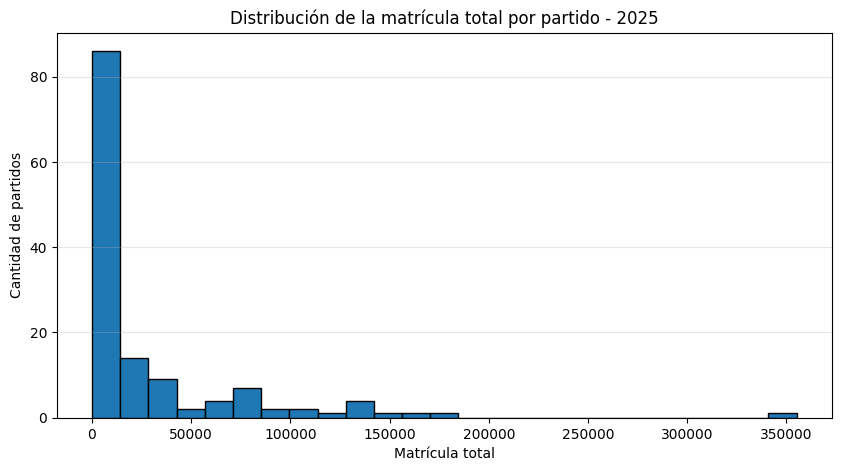

In [23]:
# Matrícula total por partido en 2025

matricula_2025 = df[df["anio"] == 2025]["matricula_total"].dropna()

print("Resumen descriptivo de la matrícula total en 2025:")
display(matricula_2025.describe().round(2))

plt.figure(figsize=(10, 5))

plt.hist(
    matricula_2025,
    bins=25,
    edgecolor="black"
)

plt.title("Distribución de la matrícula total por partido - 2025")
plt.xlabel("Matrícula total")
plt.ylabel("Cantidad de partidos")
plt.grid(axis="y", alpha=0.3)

plt.show()

#### Interpretación

La distribución de la matrícula total entre los partidos presenta una marcada asimetría hacia la derecha.

En 2025, la matrícula promedio por partido fue de aproximadamente **28.513 estudiantes**, mientras que la mediana fue considerablemente menor, con **8.775 estudiantes**. Esta diferencia entre media y mediana refleja la presencia de un grupo reducido de partidos con matrículas muy elevadas.

El 50% de los partidos presenta una matrícula comprendida aproximadamente entre **3.211 y 28.683 estudiantes**, mientras que el valor máximo alcanza los **355.183 estudiantes**.

Por lo tanto, la matrícula educativa no se distribuye de manera homogénea entre los partidos de la Provincia de Buenos Aires. Existen importantes diferencias en la escala de la demanda educativa, asociadas principalmente al tamaño poblacional de cada territorio.

Esta heterogeneidad refuerza la decisión de analizar y posteriormente estimar la demanda educativa a nivel de partido, en lugar de trabajar únicamente con valores agregados provinciales.

### 5.2 Distribución de la población

La población constituye una de las principales variables demográficas consideradas en el análisis de la demanda educativa.

A continuación se analiza la distribución de la población total entre los partidos para el año 2022.

Resumen descriptivo de la población total en 2022:


,poblacion_total
count,135.0
mean,132425.5
std,258613.4
min,1812.0
25%,16982.5
50%,37258.0
75%,117673.5
max,2374149.0


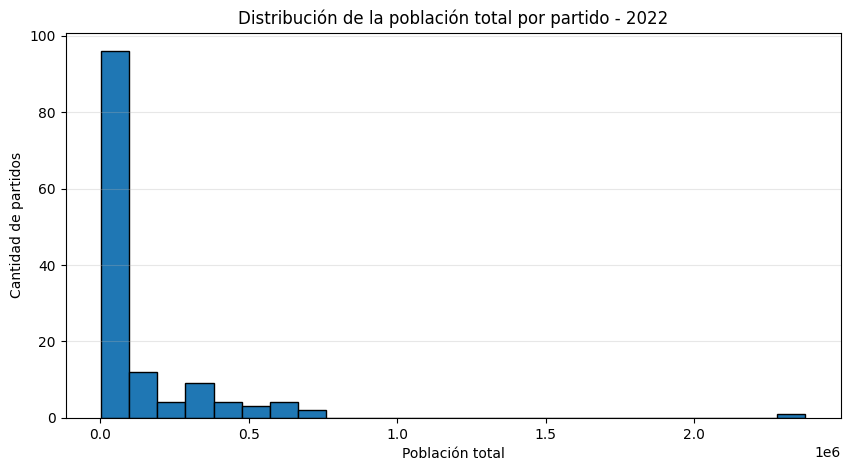

In [24]:
# Población total por partido en 2022

poblacion_2022 = df[df["anio"] == 2022]["poblacion_total"].dropna()

print("Resumen descriptivo de la población total en 2022:")
display(poblacion_2022.describe().round(2))

plt.figure(figsize=(10, 5))

plt.hist(
    poblacion_2022,
    bins=25,
    edgecolor="black"
)

plt.title("Distribución de la población total por partido - 2022")
plt.xlabel("Población total")
plt.ylabel("Cantidad de partidos")
plt.grid(axis="y", alpha=0.3)

plt.show()

#### Interpretación

La población total también presenta una distribución fuertemente asimétrica hacia la derecha entre los partidos de la Provincia de Buenos Aires.

En 2022, la población promedio fue de aproximadamente **132.426 habitantes por partido**, mientras que la mediana fue de **37.258 habitantes**. La amplia diferencia entre ambas medidas indica que unos pocos partidos con poblaciones muy elevadas incrementan considerablemente el promedio.

El 50% de los partidos presenta una población comprendida aproximadamente entre **16.983 y 117.674 habitantes**, mientras que el valor máximo alcanza los **2.374.149 habitantes**.

La distribución evidencia una marcada heterogeneidad demográfica entre los partidos. Esta característica resulta especialmente relevante para el análisis de la demanda educativa, ya que los territorios presentan escalas poblacionales muy diferentes.

### 5.3 Distribución de los nacimientos

Los nacimientos constituyen una variable demográfica relevante para el estudio de la demanda educativa, dado que permiten caracterizar el tamaño de las nuevas cohortes poblacionales.

A continuación se analiza su distribución entre los partidos para el año 2022, último año con información disponible para esta variable.

Resumen descriptivo de los nacimientos en 2022:


,nacimientos
count,135.00
mean,1215.41
std,2072.86
min,21.00
25%,160.50
50%,364.00
75%,1182.00
max,15729.00


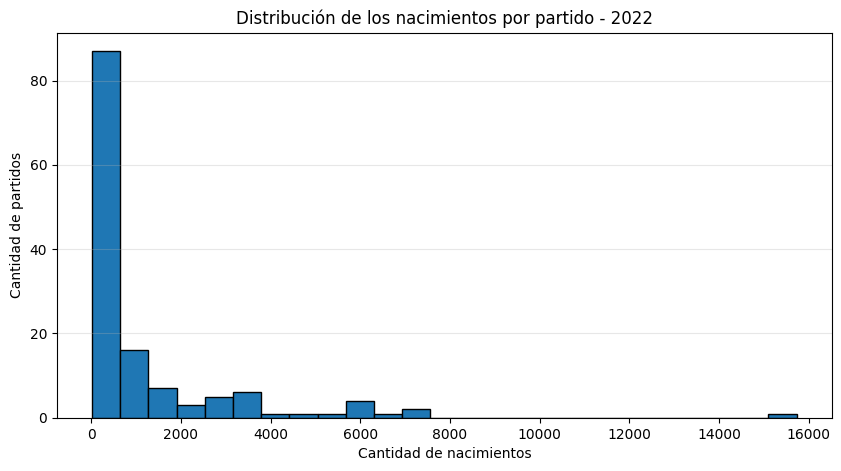

In [25]:
# Nacimientos por partido en 2022

nacimientos_2022 = df[df["anio"] == 2022]["nacimientos"].dropna()

print("Resumen descriptivo de los nacimientos en 2022:")
display(nacimientos_2022.describe().round(2))

plt.figure(figsize=(10, 5))

plt.hist(
    nacimientos_2022,
    bins=25,
    edgecolor="black"
)

plt.title("Distribución de los nacimientos por partido - 2022")
plt.xlabel("Cantidad de nacimientos")
plt.ylabel("Cantidad de partidos")
plt.grid(axis="y", alpha=0.3)

plt.show()

#### Interpretación

La cantidad de nacimientos presenta una distribución fuertemente asimétrica hacia la derecha entre los partidos de la Provincia de Buenos Aires.

En 2022 se registró un promedio de aproximadamente **1.215 nacimientos por partido**, mientras que la mediana fue de **364 nacimientos**. Esta diferencia indica que unos pocos partidos con una cantidad muy elevada de nacimientos incrementan considerablemente el promedio.

El 50% de los partidos registró aproximadamente entre **161 y 1.182 nacimientos**, mientras que el valor máximo alcanzó los **15.729 nacimientos**.

Al igual que en la población y la matrícula, se observa una marcada heterogeneidad territorial. Los partidos de mayor tamaño poblacional concentran una mayor cantidad absoluta de nacimientos, por lo que posteriormente será importante analizar esta variable en conjunto con el tamaño poblacional y con la evolución de la matrícula.

Además, al tratarse de una variable vinculada con la formación de futuras cohortes en edad escolar, su evolución temporal será analizada posteriormente en relación con la demanda educativa.

### 5.4 Distribución de variables socioeconómicas y habitacionales

Además de las variables demográficas y educativas, el dataset incorpora indicadores socioeconómicos y habitacionales provenientes del Censo 2022.

Para caracterizar su distribución territorial se seleccionaron cuatro variables representativas: tasa de empleo, tasa de desocupación, porcentaje de hogares con acceso a agua de red y porcentaje de hogares con cloaca.

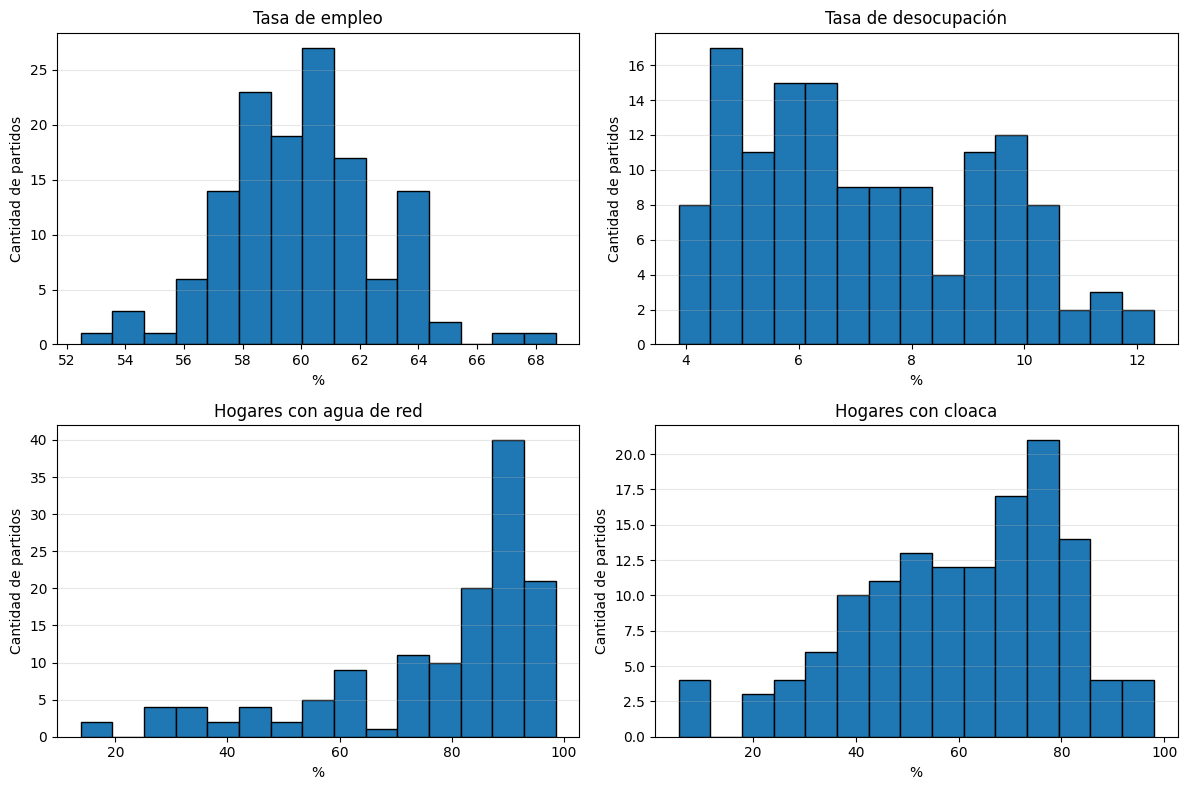

,tasa_empleo,tasa_desocupacion,porcentaje_hogares_agua_red,porcentaje_hogares_cloaca
count,135.00,135.00,135.00,135.00
mean,59.98,7.22,77.13,60.12
std,2.63,2.13,20.05,19.95
min,52.48,3.88,13.83,5.52
25%,58.26,5.51,71.22,46.97
50%,60.09,6.72,85.83,62.33
75%,61.54,9.16,91.01,76.02
max,68.68,12.29,98.55,97.97


In [26]:
# Variables socioeconómicas y habitacionales - 2022

df_2022 = df[df["anio"] == 2022]

variables_socioeconomicas = {
    "tasa_empleo": "Tasa de empleo",
    "tasa_desocupacion": "Tasa de desocupación",
    "porcentaje_hogares_agua_red": "Hogares con agua de red",
    "porcentaje_hogares_cloaca": "Hogares con cloaca"
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (variable, titulo) in zip(axes.flatten(), variables_socioeconomicas.items()):

    datos = df_2022[variable].dropna()

    ax.hist(
        datos,
        bins=15,
        edgecolor="black"
    )

    ax.set_title(titulo)
    ax.set_xlabel("%")
    ax.set_ylabel("Cantidad de partidos")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Resumen descriptivo

display(
    df_2022[list(variables_socioeconomicas.keys())]
    .describe()
    .round(2)
)

#### Interpretación

Las variables socioeconómicas y habitacionales presentan distribuciones diferentes a las observadas en las variables de volumen, como población, matrícula y nacimientos.

La **tasa de empleo** presenta una distribución relativamente concentrada entre los partidos. En 2022 registró una media de **59,98%** y una mediana de **60,09%**, con valores comprendidos entre **52,48% y 68,68%**.

La **tasa de desocupación** mostró una mayor variabilidad territorial, con una media de **7,22%** y valores entre **3,88% y 12,29%**.

En los indicadores habitacionales se observan diferencias territoriales más marcadas. El porcentaje de hogares con **agua de red** presentó una media de **77,13%**, aunque los valores variaron desde **13,83% hasta 98,55%**. Además, la mediana de **85,83%** es superior a la media, debido a la presencia de partidos con niveles considerablemente menores de acceso.

El porcentaje de hogares con **cloaca** presentó una media de **60,12%** y una mediana de **62,33%**, con un rango amplio entre **5,52% y 97,97%**.

En conjunto, estos resultados muestran que existen diferencias socioeconómicas y, especialmente, habitacionales entre los partidos de la Provincia de Buenos Aires. Estas variables serán posteriormente analizadas en relación con los indicadores educativos para determinar si presentan asociaciones con la demanda educativa.

## 6. Análisis bivariado

El análisis bivariado permite estudiar la relación entre dos variables y detectar patrones que pueden resultar relevantes para comprender la demanda educativa.

En este apartado se analizan principalmente las relaciones entre la matrícula y variables demográficas, territoriales y socioeconómicas. Las asociaciones observadas son de carácter descriptivo y no implican necesariamente relaciones causales.

Correlación entre población de 0-17 años y matrícula total: 0.985


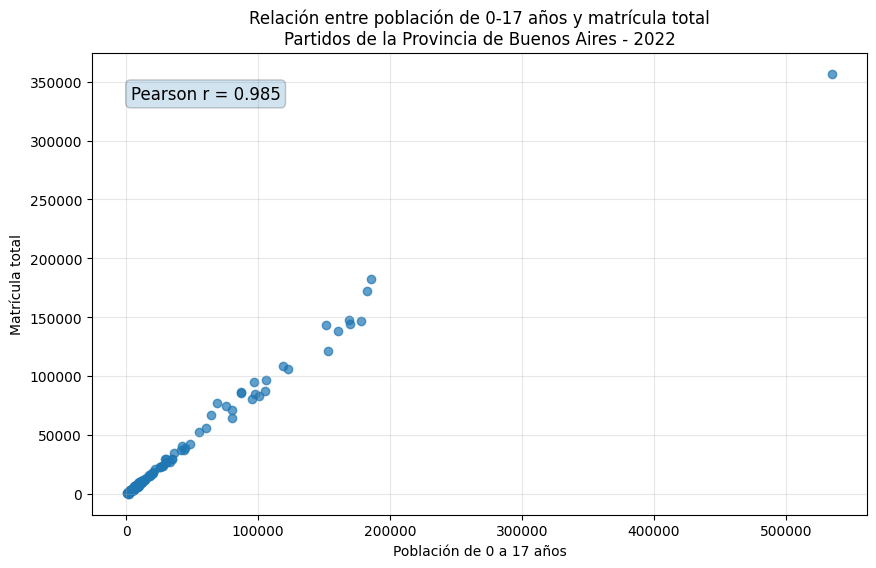

In [27]:
# Población en edad educativa (0-17 años)

df_2022 = df[df["anio"] == 2022].copy()

df_2022["poblacion_0_17"] = (
    df_2022["poblacion_0_5"] +
    df_2022["poblacion_6_11"] +
    df_2022["poblacion_12_17"]
)

# Correlación de Pearson
correlacion_poblacion_matricula = (
    df_2022["poblacion_0_17"]
    .corr(df_2022["matricula_total"])
)

print(
    "Correlación entre población de 0-17 años y matrícula total:",
    round(correlacion_poblacion_matricula, 3)
)

# Gráfico
plt.figure(figsize=(10, 6))

plt.scatter(
    df_2022["poblacion_0_17"],
    df_2022["matricula_total"],
    alpha=0.7
)

plt.xlabel("Población de 0 a 17 años")
plt.ylabel("Matrícula total")

plt.title(
    "Relación entre población de 0-17 años y matrícula total\n"
    "Partidos de la Provincia de Buenos Aires - 2022"
)

plt.text(
    0.05,
    0.90,
    f"Pearson r = {correlacion_poblacion_matricula:.3f}",
    transform=plt.gca().transAxes,
    fontsize=12,
    bbox=dict(boxstyle="round", alpha=0.2)
)

plt.grid(alpha=0.3)
plt.show()

#### Interpretación

Se observa una relación positiva muy fuerte entre la población de 0 a 17 años y la matrícula total de los partidos en 2022. El coeficiente de correlación de Pearson fue de **r = 0,985**.

Esto indica que los partidos con una mayor cantidad de población en edades educativas tienden también a presentar una mayor matrícula.

El resultado es coherente con la naturaleza de la demanda educativa y muestra que el tamaño de la población en edad escolar constituye una variable estrechamente asociada con el volumen de matrícula.

Sin embargo, esta asociación es transversal y corresponde al año 2022, por lo que no implica por sí sola una relación causal ni permite explicar la evolución temporal de la matrícula.

### 6.2 Relación entre nacimientos y matrícula

Los nacimientos constituyen una variable demográfica potencialmente relevante para analizar la evolución futura de la demanda educativa.

Como primera aproximación, se analiza la relación transversal entre la cantidad de nacimientos y la matrícula total de los partidos durante 2022.

Esta comparación permite determinar si los partidos con mayor volumen de nacimientos también presentan mayores niveles de matrícula. Sin embargo, no debe interpretarse como una relación temporal directa entre los nacimientos de 2022 y la matrícula del mismo año.

Correlación entre nacimientos y matrícula total: 0.996


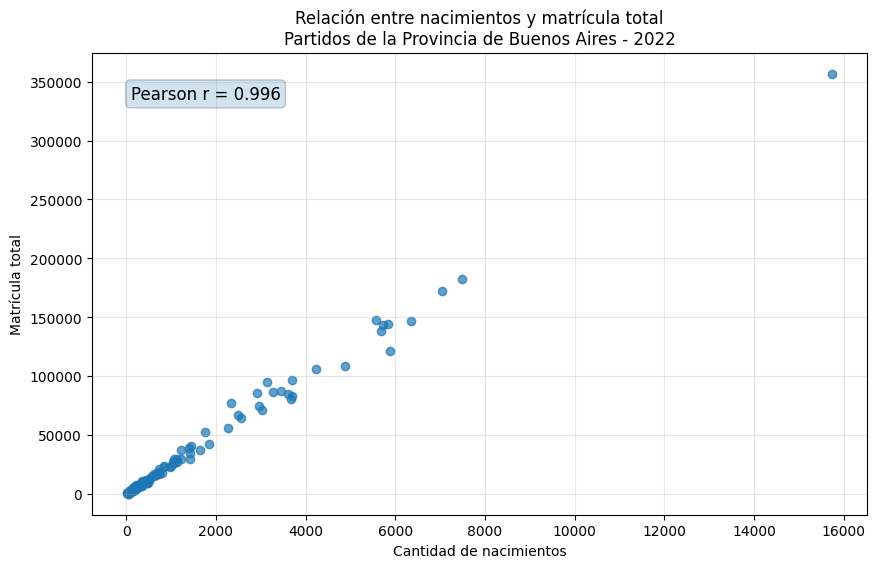

In [28]:
# Relación entre nacimientos y matrícula total - 2022

df_2022 = df[df["anio"] == 2022].copy()

correlacion_nacimientos_matricula = (
    df_2022["nacimientos"]
    .corr(df_2022["matricula_total"])
)

print(
    "Correlación entre nacimientos y matrícula total:",
    round(correlacion_nacimientos_matricula, 3)
)

plt.figure(figsize=(10, 6))

plt.scatter(
    df_2022["nacimientos"],
    df_2022["matricula_total"],
    alpha=0.7
)

plt.xlabel("Cantidad de nacimientos")
plt.ylabel("Matrícula total")

plt.title(
    "Relación entre nacimientos y matrícula total\n"
    "Partidos de la Provincia de Buenos Aires - 2022"
)

plt.text(
    0.05,
    0.90,
    f"Pearson r = {correlacion_nacimientos_matricula:.3f}",
    transform=plt.gca().transAxes,
    fontsize=12,
    bbox=dict(boxstyle="round", alpha=0.2)
)

plt.grid(alpha=0.3)
plt.show()

#### Interpretación

Se observa una relación positiva muy fuerte entre la cantidad de nacimientos y la matrícula total de los partidos en 2022. El coeficiente de correlación de Pearson fue de **r = 0,996**.

Esto indica que los partidos que registran una mayor cantidad de nacimientos tienden también a presentar mayores volúmenes de matrícula.

Sin embargo, este resultado debe interpretarse con cautela. La correlación no significa que los nacimientos ocurridos en 2022 generen directamente la matrícula observada durante ese mismo año. Ambas son variables de volumen y están fuertemente relacionadas con el tamaño poblacional de cada partido: los partidos más poblados tienden a concentrar tanto más nacimientos como más estudiantes.

Por lo tanto, esta asociación transversal evidencia principalmente diferencias de escala demográfica entre los partidos. La posible relación temporal entre nacimientos y demanda educativa deberá analizarse posteriormente considerando el desfase existente entre el nacimiento de una cohorte y su ingreso a los distintos niveles educativos.

### 6.3 Factores socioeconómicos y asistencia educativa

Para explorar la posible relación entre el contexto socioeconómico de los partidos y las características educativas, se analiza la tasa de asistencia censal en relación con algunos indicadores socioeconómicos y habitacionales.

Se seleccionan la tasa de desocupación y el porcentaje de hogares sin baño por haber presentado las asociaciones más elevadas durante el análisis exploratorio. Los resultados corresponden a una comparación transversal entre los partidos durante 2022 y no deben interpretarse como relaciones causales.

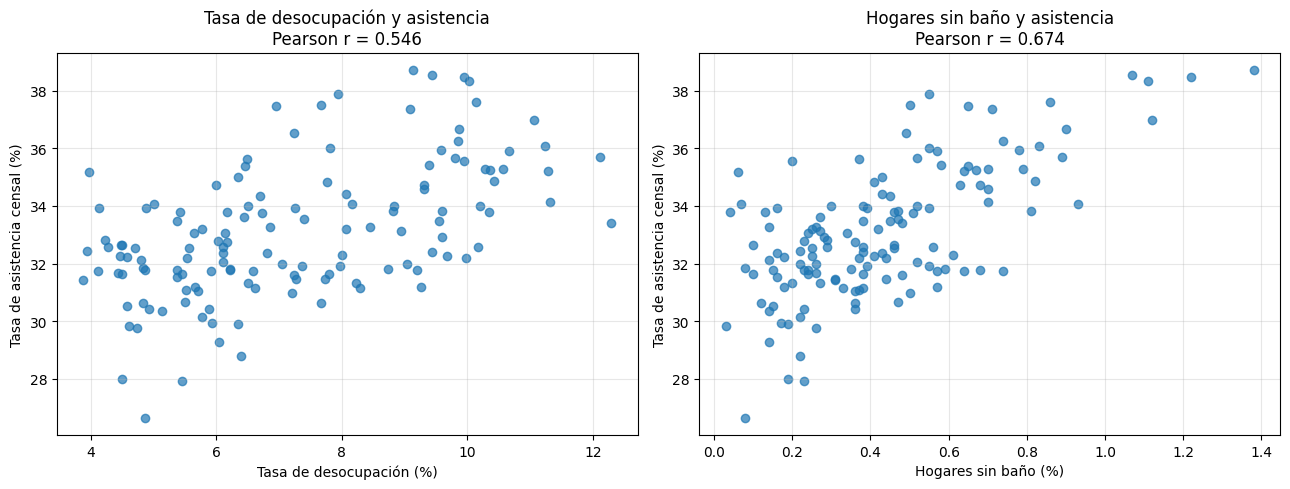

In [29]:
# Relaciones socioeconómicas con la tasa de asistencia - 2022

variables_bivariadas = {
    "tasa_desocupacion": "Tasa de desocupación",
    "porcentaje_hogares_sin_banio": "Hogares sin baño"
}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (variable, etiqueta) in zip(
    axes,
    variables_bivariadas.items()
):

    datos = df_2022[
        [variable, "tasa_asistencia_censo_2022"]
    ].dropna()

    correlacion = datos[variable].corr(
        datos["tasa_asistencia_censo_2022"]
    )

    ax.scatter(
        datos[variable],
        datos["tasa_asistencia_censo_2022"],
        alpha=0.7
    )

    ax.set_xlabel(f"{etiqueta} (%)")
    ax.set_ylabel("Tasa de asistencia censal (%)")

    ax.set_title(
        f"{etiqueta} y asistencia\n"
        f"Pearson r = {correlacion:.3f}"
    )

    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Interpretación

Los resultados muestran asociaciones positivas entre algunos indicadores socioeconómicos y la tasa de asistencia censal de los partidos en 2022.

La **tasa de desocupación** presenta una correlación positiva moderada con la tasa de asistencia (r = 0,546), mientras que el **porcentaje de hogares sin baño** presenta una asociación positiva más elevada (r = 0,674).

Estas relaciones no deben interpretarse de manera causal. Los resultados no indican que una mayor desocupación o una mayor proporción de hogares sin baño produzcan una mayor asistencia educativa. Las asociaciones observadas pueden estar vinculadas con diferencias demográficas, sociales y territoriales entre los partidos.

Por lo tanto, estos indicadores se consideran características del contexto socioeconómico de cada partido que podrían aportar información complementaria al análisis de la demanda educativa.

## 7. Correlaciones y colinealidad

### 7.1 Matriz de correlaciones

Se analiza la correlación entre las principales variables demográficas, educativas y socioeconómicas disponibles para 2022.

El objetivo es identificar variables fuertemente relacionadas entre sí y detectar posibles situaciones de colinealidad que deberán considerarse posteriormente durante la selección de variables para los modelos predictivos.

In [30]:
# Variables seleccionadas para el análisis de correlaciones

variables_correlacion = [
    "matricula_total",
    "poblacion_total",
    "poblacion_0_5",
    "poblacion_6_11",
    "poblacion_12_17",
    "nacimientos",
    "densidad_2022",
    "tasa_actividad",
    "tasa_empleo",
    "tasa_desocupacion",
    "porcentaje_hogares_agua_red",
    "porcentaje_hogares_cloaca",
    "porcentaje_hogares_sin_banio",
    "tasa_asistencia_censo_2022"
]

# Dataset correspondiente a 2022
datos_correlacion = df[df["anio"] == 2022][variables_correlacion].copy()

# Matriz de correlación de Pearson
matriz_correlacion = datos_correlacion.corr(method="pearson")

matriz_correlacion.round(3)

,matricula_total,poblacion_total,poblacion_0_5,poblacion_6_11,poblacion_12_17,nacimientos,densidad_2022,tasa_actividad,tasa_empleo,tasa_desocupacion,porcentaje_hogares_agua_red,porcentaje_hogares_cloaca,porcentaje_hogares_sin_banio,tasa_asistencia_censo_2022
matricula_total,1.000,0.968,0.980,0.985,0.989,0.996,0.649,-0.018,-0.320,0.584,-0.108,-0.108,0.407,0.331
poblacion_total,0.968,1.000,0.993,0.992,0.992,0.973,0.599,-0.023,-0.275,0.494,-0.043,-0.063,0.340,0.246
poblacion_0_5,0.980,0.993,1.000,0.999,0.997,0.988,0.588,-0.021,-0.289,0.523,-0.098,-0.113,0.400,0.300
poblacion_6_11,0.985,0.992,0.999,1.000,0.999,0.991,0.605,-0.021,-0.296,0.536,-0.098,-0.111,0.399,0.304
poblacion_12_17,0.989,0.992,0.997,0.999,1.000,0.992,0.622,-0.025,-0.304,0.545,-0.091,-0.102,0.392,0.298
nacimientos,0.996,0.973,0.988,0.991,0.992,1.000,0.615,-0.017,-0.309,0.567,-0.118,-0.129,0.425,0.337
densidad_2022,0.649,0.599,0.588,0.605,0.622,0.615,1.000,-0.014,-0.286,0.526,-0.082,-0.022,0.174,0.123
tasa_actividad,-0.018,-0.023,-0.021,-0.021,-0.025,-0.017,-0.014,1.000,0.869,-0.319,-0.172,-0.219,-0.133,0.186
tasa_empleo,-0.320,-0.275,-0.289,-0.296,-0.304,-0.309,-0.286,0.869,1.000,-0.746,0.006,-0.076,-0.401,-0.155
tasa_desocupacion,0.584,0.494,0.523,0.536,0.545,0.567,0.526,-0.319,-0.746,1.000,-0.242,-0.145,0.583,0.546


### 7.2 Identificación de correlaciones elevadas

A partir de la matriz de correlaciones se identifican los pares de variables que presentan una correlación de Pearson elevada en valor absoluto (|r| ≥ 0,80).

Este análisis permite detectar variables que contienen información estadísticamente muy similar y que podrían generar problemas de colinealidad si fueran incorporadas simultáneamente en determinados modelos predictivos.

In [31]:
# Identificación de pares con correlación elevada

pares_correlacion_alta = []

for i in range(len(matriz_correlacion.columns)):
    for j in range(i + 1, len(matriz_correlacion.columns)):

        variable_1 = matriz_correlacion.columns[i]
        variable_2 = matriz_correlacion.columns[j]
        correlacion = matriz_correlacion.iloc[i, j]

        if abs(correlacion) >= 0.80:
            pares_correlacion_alta.append({
                "variable_1": variable_1,
                "variable_2": variable_2,
                "correlacion": correlacion
            })

correlaciones_altas = pd.DataFrame(pares_correlacion_alta)

correlaciones_altas["correlacion_absoluta"] = (
    correlaciones_altas["correlacion"].abs()
)

correlaciones_altas = correlaciones_altas.sort_values(
    "correlacion_absoluta",
    ascending=False
)

correlaciones_altas[
    ["variable_1", "variable_2", "correlacion"]
].round(3)

,variable_1,variable_2,correlacion
9,poblacion_0_5,poblacion_6_11,0.999
12,poblacion_6_11,poblacion_12_17,0.999
10,poblacion_0_5,poblacion_12_17,0.997
4,matricula_total,nacimientos,0.996
5,poblacion_total,poblacion_0_5,0.993
14,poblacion_12_17,nacimientos,0.992
6,poblacion_total,poblacion_6_11,0.992
7,poblacion_total,poblacion_12_17,0.992
13,poblacion_6_11,nacimientos,0.991
3,matricula_total,poblacion_12_17,0.989


#### Interpretación

Se identificaron varias correlaciones elevadas entre las variables demográficas y educativas analizadas.

Las relaciones más fuertes se observan entre los distintos grupos de población por edad. La población de 0 a 5 años y la población de 6 a 11 años presentan una correlación de r = 0,999; el mismo valor se observa entre la población de 6 a 11 y la de 12 a 17 años. Esto indica que los partidos con mayor cantidad de población infantil en un grupo etario tienden también a presentar mayores cantidades en los demás grupos.

También se observan correlaciones muy elevadas entre la población total, los grupos de población en edad educativa y los nacimientos. Estas asociaciones reflejan principalmente diferencias de tamaño entre los partidos: los partidos más poblados tienden a concentrar más nacimientos, mayor población en edad educativa y mayor matrícula.

La matrícula total presenta correlaciones particularmente elevadas con los nacimientos (r = 0,996), la población de 12 a 17 años (r = 0,989), la población de 6 a 11 años (r = 0,985) y la población de 0 a 5 años (r = 0,980).

Además, entre las variables económicas se observa una correlación elevada entre la tasa de actividad y la tasa de empleo (r = 0,869).

Estos resultados evidencian la existencia de colinealidad entre algunas variables explicativas. Sin embargo, en esta etapa exploratoria no se eliminarán variables. La selección definitiva deberá realizarse posteriormente según el modelo utilizado, la disponibilidad temporal de cada variable y su aporte predictivo.

### 7.3 MAPA DE CALOR DE CORRELACIONES



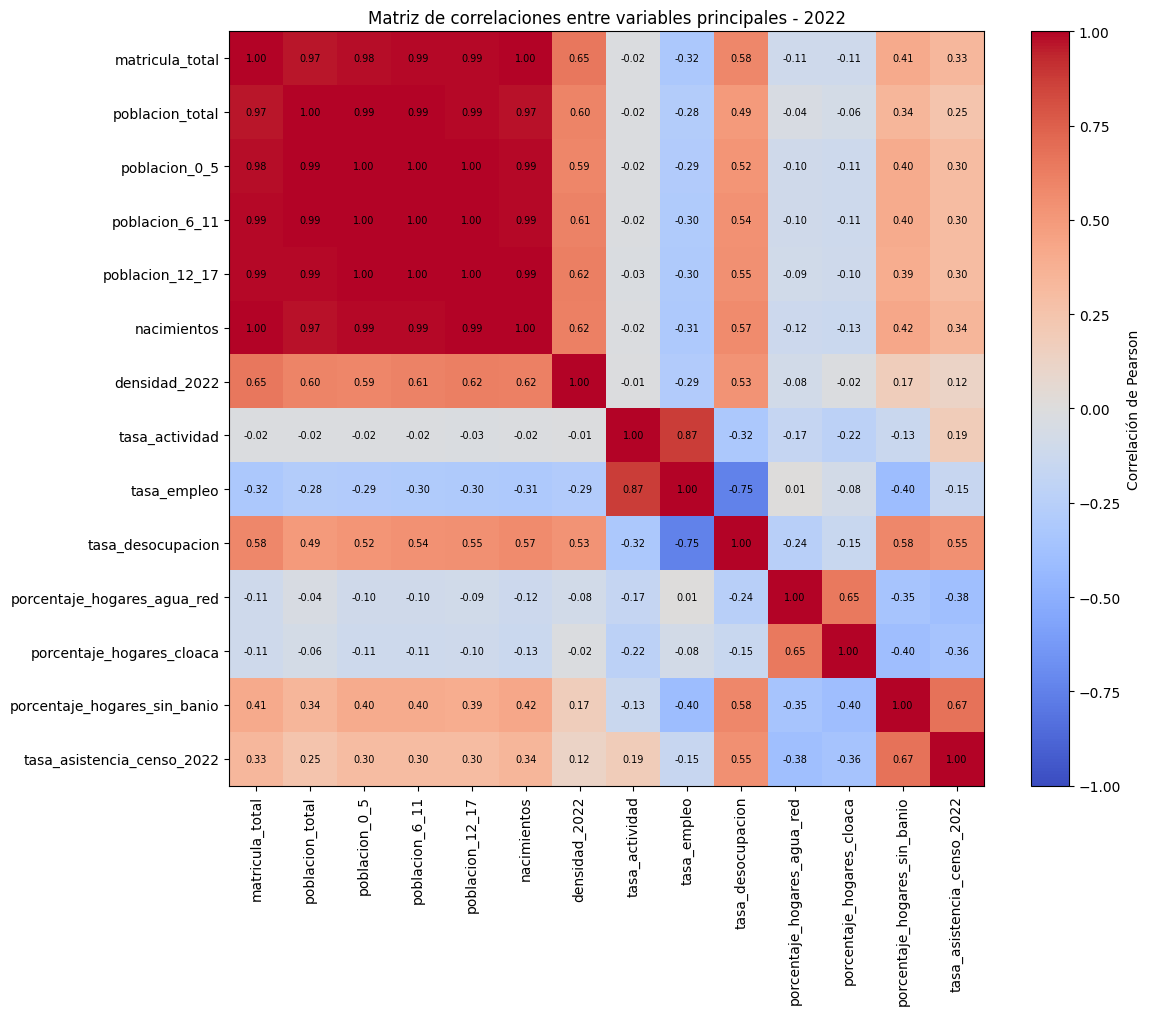

In [32]:
fig, ax = plt.subplots(figsize=(12, 10))

imagen = ax.imshow(
    matriz_correlacion,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(matriz_correlacion.columns)))
ax.set_yticks(range(len(matriz_correlacion.columns)))

ax.set_xticklabels(
    matriz_correlacion.columns,
    rotation=90
)

ax.set_yticklabels(
    matriz_correlacion.columns
)

# Mostrar el valor de cada correlación
for i in range(len(matriz_correlacion.columns)):
    for j in range(len(matriz_correlacion.columns)):
        ax.text(
            j,
            i,
            f"{matriz_correlacion.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=7
        )

plt.colorbar(
    imagen,
    ax=ax,
    label="Correlación de Pearson"
)

plt.title(
    "Matriz de correlaciones entre variables principales - 2022"
)

plt.tight_layout()
plt.show()

#### Interpretación del mapa de correlaciones

El mapa de correlaciones permite observar dos comportamientos principales.

En primer lugar, se identifica un bloque de correlaciones muy elevadas entre la matrícula total, la población total, los distintos grupos de población en edad educativa y los nacimientos. Esto refleja principalmente el efecto del tamaño poblacional de los partidos: aquellos con mayor población tienden a concentrar también mayor cantidad de niños y adolescentes, nacimientos y estudiantes matriculados.

En segundo lugar, las variables socioeconómicas presentan relaciones más moderadas y heterogéneas. Se destaca la asociación positiva entre la tasa de actividad y la tasa de empleo (r = 0,869), así como la relación negativa entre empleo y desocupación (r = -0,746).

La elevada correlación existente entre varias variables demográficas indica una posible situación de colinealidad. Este aspecto deberá considerarse posteriormente durante la selección de variables y el desarrollo de los modelos predictivos, evitando incorporar de manera automática múltiples variables que aporten información altamente redundante.

Las correlaciones observadas son asociaciones estadísticas y no implican relaciones causales.

## 8. Análisis temporal

El análisis temporal permite estudiar cómo evolucionaron las principales variables vinculadas con la demanda educativa a lo largo del período disponible.

En particular, se analiza la evolución de los nacimientos y de la matrícula educativa, tanto a nivel general como por nivel educativo. Esto permite identificar tendencias, cambios de comportamiento y posibles relaciones temporales relevantes para la posterior construcción de los modelos predictivos.

### 8.1 Evolución histórica de los nacimientos

Los nacimientos constituyen una variable demográfica de especial interés para el análisis de la demanda educativa, ya que representan las cohortes que posteriormente ingresarán al sistema educativo.

Se analiza su evolución agregada para el conjunto de los partidos de la Provincia de Buenos Aires entre 2012 y 2022.

Nacimientos por año:


,nacimientos
anio,
2012,289720.0
2013,290116.0
2014,293943.0
2015,283863.0
2016,268841.0
2017,260846.0
2018,253242.0
2019,228455.0
2020,201232.0



Variación de nacimientos entre 2012 y 2022: -43.37%


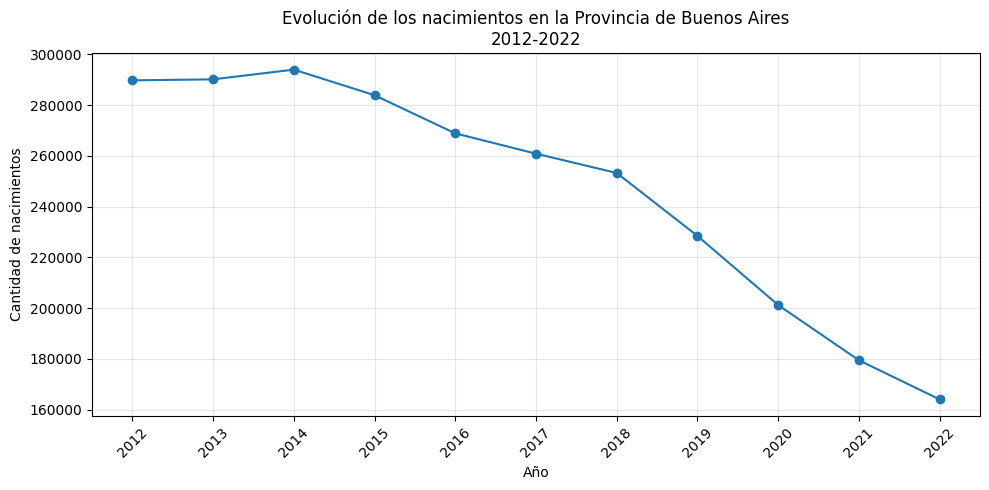

In [33]:
# Evolución provincial de los nacimientos

nacimientos_anuales = (
    df[df["anio"].between(2012, 2022)]
    .groupby("anio")["nacimientos"]
    .sum()
)

print("Nacimientos por año:")
display(nacimientos_anuales.to_frame())

variacion_nacimientos = (
    (nacimientos_anuales.iloc[-1] - nacimientos_anuales.iloc[0])
    / nacimientos_anuales.iloc[0]
    * 100
)

print(
    f"\nVariación de nacimientos entre 2012 y 2022: "
    f"{variacion_nacimientos:.2f}%"
)

plt.figure(figsize=(10, 5))

plt.plot(
    nacimientos_anuales.index,
    nacimientos_anuales.values,
    marker="o"
)

plt.title(
    "Evolución de los nacimientos en la Provincia de Buenos Aires\n2012-2022"
)

plt.xlabel("Año")
plt.ylabel("Cantidad de nacimientos")

plt.xticks(nacimientos_anuales.index, rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Interpretación

Los nacimientos presentan una tendencia descendente marcada durante el período analizado. Entre 2012 y 2014 se mantuvieron relativamente estables, alcanzando un máximo de 293.943 nacimientos en 2014. A partir de 2015 comienza una disminución sostenida, que se vuelve especialmente pronunciada en los últimos años de la serie.

En 2022 se registraron 164.081 nacimientos, lo que representa una reducción del 43,37% respecto de 2012.

Esta evolución resulta especialmente relevante para el análisis de la demanda educativa, ya que una reducción sostenida en el tamaño de las nuevas cohortes podría posteriormente reflejarse en una menor cantidad de población en edad escolar. Sin embargo, esta relación debe analizarse considerando el desfase temporal existente entre el nacimiento y el ingreso a los distintos niveles educativos.

### 8.2 EVOLUCIÓN HISTÓRICA DE LA MATRÍCULA TOTAL




8.2 EVOLUCIÓN HISTÓRICA DE LA MATRÍCULA TOTAL

Matrícula total por año:
anio
2012    3774129.0
2013    3797291.0
2014    3819925.0
2015    3843411.0
2016    3898910.0
2017    3944951.0
2018    3984647.0
2019    3998713.0
2020    4037971.0
2021    4038876.0
2022    4031051.0
2023    4009704.0
2024    3931924.0
2025    3849256.0
Name: matricula_total, dtype: float64

Variación de la matrícula total entre 2012 y 2025: 1.99%

Mayor matrícula: 4,038,876 en 2021
Menor matrícula: 3,774,129 en 2012


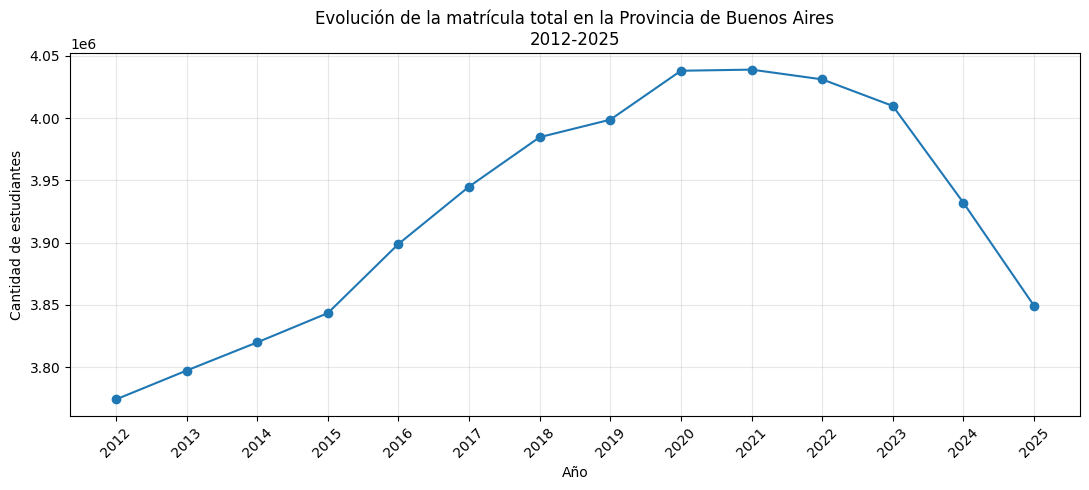

In [34]:
print("\n8.2 EVOLUCIÓN HISTÓRICA DE LA MATRÍCULA TOTAL")

# Nos quedamos con los años que tienen matrícula observada
matricula_anual = (
    df[
        (df["anio"] >= 2012) &
        (df["anio"] <= 2025)
    ]
    .groupby("anio")["matricula_total"]
    .sum(min_count=1)
)

print("\nMatrícula total por año:")
print(matricula_anual)

# Variación entre 2012 y 2025
matricula_2012 = matricula_anual.loc[2012]
matricula_2025 = matricula_anual.loc[2025]

variacion_matricula = (
    (matricula_2025 - matricula_2012)
    / matricula_2012
) * 100

print(
    f"\nVariación de la matrícula total entre 2012 y 2025: "
    f"{variacion_matricula:.2f}%"
)

# Año con mayor y menor matrícula
anio_max = matricula_anual.idxmax()
anio_min = matricula_anual.idxmin()

print(
    f"\nMayor matrícula: {matricula_anual.loc[anio_max]:,.0f} "
    f"en {anio_max}"
)

print(
    f"Menor matrícula: {matricula_anual.loc[anio_min]:,.0f} "
    f"en {anio_min}"
)

# Gráfico
plt.figure(figsize=(11, 5))

plt.plot(
    matricula_anual.index,
    matricula_anual.values,
    marker="o"
)

plt.title(
    "Evolución de la matrícula total en la Provincia de Buenos Aires\n"
    "2012-2025"
)

plt.xlabel("Año")
plt.ylabel("Cantidad de estudiantes")

plt.xticks(
    matricula_anual.index,
    rotation=45
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Interpretación

La matrícula total de la Provincia de Buenos Aires presenta dos etapas diferenciadas durante el período 2012-2025.

Entre 2012 y 2021 se observa una tendencia general de crecimiento, pasando de 3.774.129 estudiantes en 2012 a un máximo de 4.038.876 en 2021. A partir de ese momento la tendencia cambia: la matrícula comienza a disminuir y alcanza 3.849.256 estudiantes en 2025.

Considerando los extremos del período, la matrícula de 2025 todavía se encuentra un 1,99% por encima de la registrada en 2012. Sin embargo, este valor oculta el cambio reciente de tendencia, ya que entre 2021 y 2025 la matrícula disminuyó aproximadamente un 4,69%.

Al comparar este comportamiento con la evolución de los nacimientos, se observa que la fuerte disminución de los nacimientos comenzó varios años antes que la caída reciente de la matrícula. Esto resulta compatible con la existencia de un desfase temporal entre los cambios demográficos y su posible manifestación posterior en la demanda educativa.

Esta comparación es descriptiva y no permite establecer por sí sola una relación causal.

### 8.3 EVOLUCIÓN DE LA MATRÍCULA POR NIVEL EDUCATIVO





8.3 EVOLUCIÓN DE LA MATRÍCULA POR NIVEL EDUCATIVO

Matrícula por nivel y año:
      matricula_inicial  matricula_primaria  matricula_secundaria
anio                                                             
2012           685371.0           1664511.0             1424447.0
2013           697858.0           1664574.0             1435039.0
2014           704852.0           1675460.0             1439777.0
2015           715806.0           1682042.0             1445799.0
2016           723251.0           1693303.0             1482598.0
2017           734708.0           1703305.0             1506984.0
2018           746773.0           1710047.0             1527879.0
2019           735245.0           1721705.0             1541806.0
2020           717543.0           1734671.0             1585807.0
2021           663395.0           1734837.0             1640707.0
2022           667820.0           1721711.0             1641520.0
2023           650022.0           1707723.0             1651959

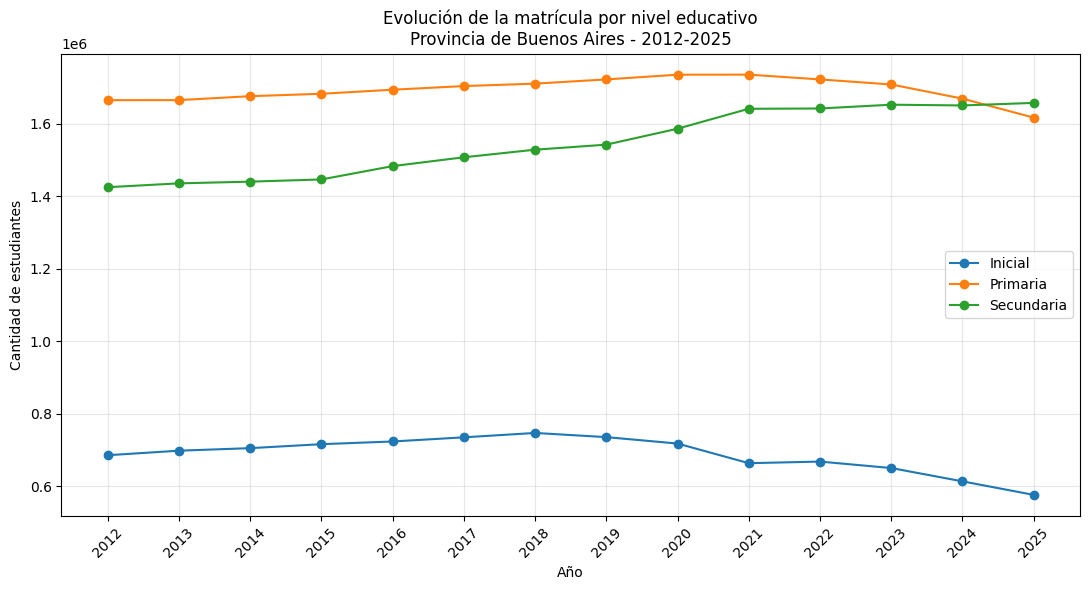

In [35]:
print("\n8.3 EVOLUCIÓN DE LA MATRÍCULA POR NIVEL EDUCATIVO")

columnas_niveles = [
    "matricula_inicial",
    "matricula_primaria",
    "matricula_secundaria"
]

# Matrícula provincial por año y nivel
matricula_niveles_anual = (
    df[
        (df["anio"] >= 2012) &
        (df["anio"] <= 2025)
    ]
    .groupby("anio")[columnas_niveles]
    .sum(min_count=1)
)

print("\nMatrícula por nivel y año:")
print(matricula_niveles_anual)

# Variación entre 2012 y 2025
variacion_niveles = (
    (
        matricula_niveles_anual.loc[2025]
        - matricula_niveles_anual.loc[2012]
    )
    / matricula_niveles_anual.loc[2012]
) * 100

print("\nVariación entre 2012 y 2025 por nivel:")
print(variacion_niveles.round(2))

# Año de matrícula máxima de cada nivel
print("\nAño de matrícula máxima por nivel:")

for columna in columnas_niveles:
    anio_max = matricula_niveles_anual[columna].idxmax()
    valor_max = matricula_niveles_anual.loc[anio_max, columna]

    print(
        f"{columna}: {valor_max:,.0f} estudiantes en {anio_max}"
    )

# Gráfico
plt.figure(figsize=(11, 6))

plt.plot(
    matricula_niveles_anual.index,
    matricula_niveles_anual["matricula_inicial"],
    marker="o",
    label="Inicial"
)

plt.plot(
    matricula_niveles_anual.index,
    matricula_niveles_anual["matricula_primaria"],
    marker="o",
    label="Primaria"
)

plt.plot(
    matricula_niveles_anual.index,
    matricula_niveles_anual["matricula_secundaria"],
    marker="o",
    label="Secundaria"
)

plt.title(
    "Evolución de la matrícula por nivel educativo\n"
    "Provincia de Buenos Aires - 2012-2025"
)

plt.xlabel("Año")
plt.ylabel("Cantidad de estudiantes")

plt.xticks(
    matricula_niveles_anual.index,
    rotation=45
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Interpretación

La evolución de la matrícula presenta comportamientos diferentes según el nivel educativo.

En el nivel Inicial, la matrícula aumentó hasta alcanzar un máximo de 746.773 estudiantes en 2018. A partir de ese año comienza una tendencia descendente, llegando a 575.986 estudiantes en 2025. En comparación con 2012, esto representa una disminución del 15,96%.

En Primaria, el crecimiento se prolongó durante más tiempo y la matrícula alcanzó su máximo en 2021, con 1.734.837 estudiantes. Desde entonces se observa una disminución progresiva, alcanzando 1.616.341 estudiantes en 2025. Entre 2012 y 2025 la variación fue de -2,89%.

Secundaria presenta un comportamiento diferente. La matrícula mantuvo una tendencia general creciente durante prácticamente todo el período y alcanzó su máximo en 2025, con 1.656.929 estudiantes. Esto representa un aumento del 16,32% respecto de 2012.

Los resultados muestran que el cambio de tendencia no se produce simultáneamente en todos los niveles educativos. La disminución aparece primero en Inicial y posteriormente en Primaria, mientras que Secundaria todavía no presenta una tendencia descendente sostenida.

Este comportamiento es compatible con un posible desplazamiento temporal de los cambios demográficos a medida que las cohortes avanzan por los distintos niveles educativos. Sin embargo, esta relación debe analizarse posteriormente mediante variables rezagadas y no implica por sí sola una relación causal.

### 8.4 DESFASE TEMPORAL ENTRE NACIMIENTOS Y MATRÍCULA INICIAL




8.4 DESFASE TEMPORAL ENTRE NACIMIENTOS Y MATRÍCULA INICIAL

Datos con rezagos:
      nacimientos  matricula_inicial  nacimientos_lag_3  nacimientos_lag_4  \
anio                                                                         
2012     289720.0           685371.0                NaN                NaN   
2013     290116.0           697858.0                NaN                NaN   
2014     293943.0           704852.0                NaN                NaN   
2015     283863.0           715806.0           289720.0                NaN   
2016     268841.0           723251.0           290116.0           289720.0   
2017     260846.0           734708.0           293943.0           290116.0   
2018     253242.0           746773.0           283863.0           293943.0   
2019     228455.0           735245.0           268841.0           283863.0   
2020     201232.0           717543.0           260846.0           268841.0   
2021     179490.0           663395.0           253242.0       

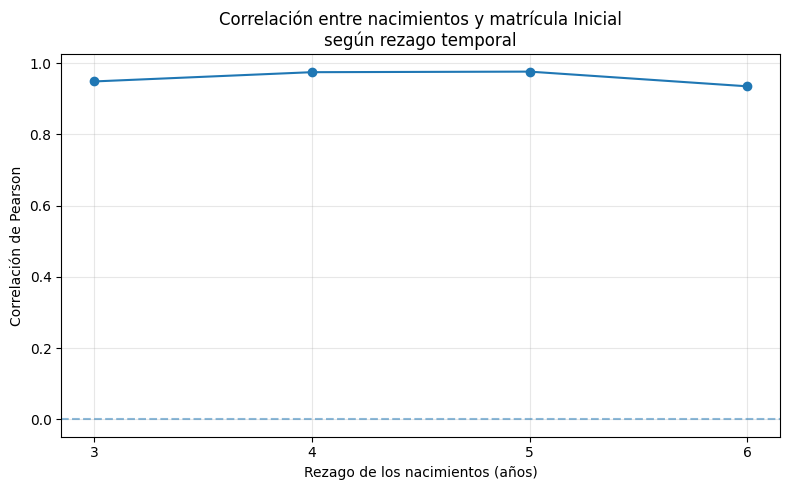

In [36]:
print("\n8.4 DESFASE TEMPORAL ENTRE NACIMIENTOS Y MATRÍCULA INICIAL")

# Serie provincial de nacimientos
nacimientos_anual = (
    df[
        (df["anio"] >= 2012) &
        (df["anio"] <= 2022)
    ]
    .groupby("anio")["nacimientos"]
    .sum(min_count=1)
)

# Serie provincial de matrícula Inicial
matricula_inicial_anual = (
    df[
        (df["anio"] >= 2012) &
        (df["anio"] <= 2025)
    ]
    .groupby("anio")["matricula_inicial"]
    .sum(min_count=1)
)

# DataFrame con ambas series
temporal_inicial = pd.DataFrame({
    "nacimientos": nacimientos_anual,
    "matricula_inicial": matricula_inicial_anual
})

for rezago in [3, 4, 5, 6]:
    temporal_inicial[f"nacimientos_lag_{rezago}"] = (
        temporal_inicial["nacimientos"].shift(rezago)
    )

print("\nDatos con rezagos:")
print(temporal_inicial)


resultados_rezagos = []

for rezago in [3, 4, 5, 6]:

    columna_lag = f"nacimientos_lag_{rezago}"

    datos_validos = temporal_inicial[
        [columna_lag, "matricula_inicial"]
    ].dropna()

    correlacion = datos_validos[
        columna_lag
    ].corr(
        datos_validos["matricula_inicial"]
    )

    resultados_rezagos.append({
        "rezago_anios": rezago,
        "correlacion": correlacion,
        "cantidad_anios_comparados": len(datos_validos)
    })

resultados_rezagos = pd.DataFrame(resultados_rezagos)

print("\nCorrelación entre nacimientos rezagados y matrícula Inicial:")
print(resultados_rezagos.round(3))

# GRÁFICO

plt.figure(figsize=(8, 5))

plt.plot(
    resultados_rezagos["rezago_anios"],
    resultados_rezagos["correlacion"],
    marker="o"
)

plt.axhline(
    y=0,
    linestyle="--",
    alpha=0.5
)

plt.title(
    "Correlación entre nacimientos y matrícula Inicial\n"
    "según rezago temporal"
)

plt.xlabel("Rezago de los nacimientos (años)")
plt.ylabel("Correlación de Pearson")

plt.xticks([3, 4, 5, 6])

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Desfase temporal entre nacimientos y matrícula Inicial.
Al comparar la evolución provincial de los nacimientos con la matrícula del nivel Inicial en años posteriores, se observaron correlaciones positivas elevadas para todos los rezagos analizados. Las mayores asociaciones se registraron con rezagos de cuatro años (r = 0,975) y cinco años (r = 0,976). Este resultado es consistente con la existencia de un desfase temporal entre los cambios demográficos y su posterior manifestación en la matrícula educativa. Sin embargo, debido a la cantidad limitada de observaciones temporales disponibles, estos resultados deben interpretarse como evidencia exploratoria y no como una relación causal.

### 8.5 DESFASE TEMPORAL ENTRE NACIMIENTOS Y NIVELES EDUCATIVOS



8.5 DESFASE TEMPORAL ENTRE NACIMIENTOS Y NIVELES EDUCATIVOS

Correlaciones según nivel y rezago temporal:
     nivel  rezago_anios  correlacion  cantidad_anios_comparados
   Inicial             3        0.949                         11
   Inicial             4        0.975                         10
   Inicial             5        0.976                          9
   Inicial             6        0.935                          8
  Primaria             6        0.903                          8
  Primaria             7        0.925                          7
  Primaria             8        0.963                          6
  Primaria             9        0.921                          5
  Primaria            10        0.568                          4
  Primaria            11          NaN                          3
Secundaria            12          NaN                          2
Secundaria            13          NaN                          1


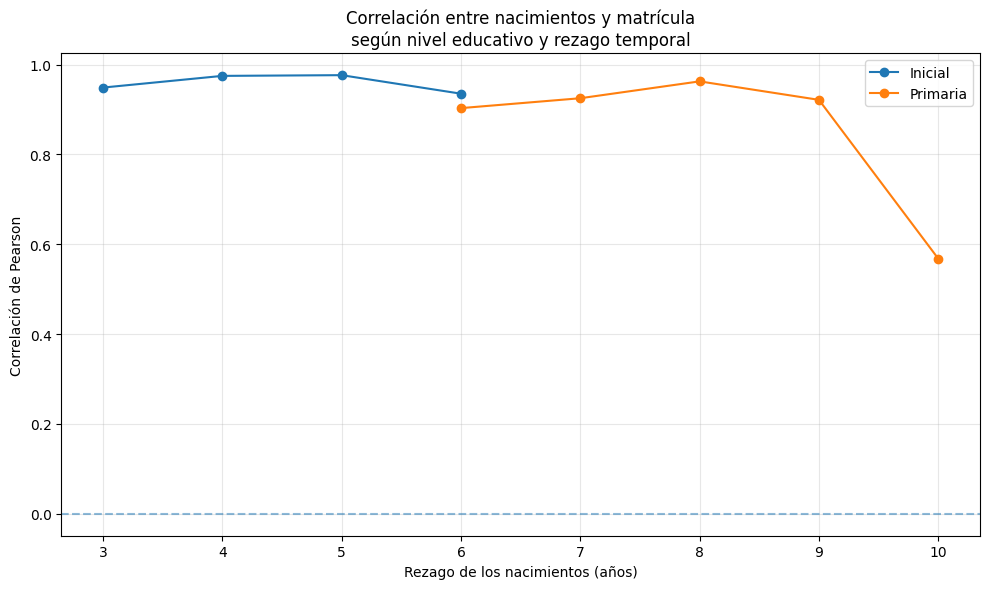

In [40]:
print("\n8.5 DESFASE TEMPORAL ENTRE NACIMIENTOS Y NIVELES EDUCATIVOS")

# Crear serie provincial anual
serie_temporal = (
    df[
        (df["anio"] >= 2012) &
        (df["anio"] <= 2025)
    ]
    .groupby("anio")[
        [
            "nacimientos",
            "matricula_inicial",
            "matricula_primaria",
            "matricula_secundaria"
        ]
    ]
    .sum(min_count=1)
)

# Rezagos a analizar según nivel educativo
rezagos_por_nivel = {
    "Inicial": {
        "columna": "matricula_inicial",
        "rezagos": [3, 4, 5, 6]
    },

    "Primaria": {
        "columna": "matricula_primaria",
        "rezagos": [6, 7, 8, 9, 10, 11]
    },

    "Secundaria": {
        "columna": "matricula_secundaria",
        "rezagos": [12, 13]
    }
}

resultados_rezagos = []

for nivel, informacion in rezagos_por_nivel.items():

    columna_matricula = informacion["columna"]

    for rezago in informacion["rezagos"]:

        columna_rezago = f"nacimientos_lag_{rezago}"

        serie_temporal[columna_rezago] = (
            serie_temporal["nacimientos"].shift(rezago)
        )

        datos_validos = serie_temporal[
            [columna_rezago, columna_matricula]
        ].dropna()

        cantidad_anios = len(datos_validos)

        # Solo calculamos correlación si hay al menos 4 observaciones
        if cantidad_anios >= 4:

            correlacion = datos_validos[
                columna_rezago
            ].corr(
                datos_validos[columna_matricula]
            )

        else:
            correlacion = float("nan")

        resultados_rezagos.append(
            {
                "nivel": nivel,
                "rezago_anios": rezago,
                "correlacion": correlacion,
                "cantidad_anios_comparados": cantidad_anios
            }
        )

# Convertir resultados en DataFrame
resultados_rezagos = pd.DataFrame(resultados_rezagos)

print("\nCorrelaciones según nivel y rezago temporal:")

print(
    resultados_rezagos
    .round(3)
    .to_string(index=False)
)

# GRÁFICO

plt.figure(figsize=(10, 6))

for nivel in ["Inicial", "Primaria"]:

    datos_nivel = resultados_rezagos[
        resultados_rezagos["nivel"] == nivel
    ].dropna(subset=["correlacion"])

    plt.plot(
        datos_nivel["rezago_anios"],
        datos_nivel["correlacion"],
        marker="o",
        label=nivel
    )

plt.axhline(
    y=0,
    linestyle="--",
    alpha=0.5
)

plt.xlabel("Rezago de los nacimientos (años)")
plt.ylabel("Correlación de Pearson")

plt.title(
    "Correlación entre nacimientos y matrícula\n"
    "según nivel educativo y rezago temporal"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Desfase temporal según nivel educativo. El análisis de rezagos muestra asociaciones positivas elevadas entre los nacimientos y la matrícula de los niveles Inicial y Primario. En Inicial, las mayores correlaciones se observaron con rezagos de cuatro y cinco años (r = 0,975 y r = 0,976), mientras que en Primaria la mayor asociación se registró con un rezago de ocho años (r = 0,963). Estos resultados son compatibles con un desplazamiento temporal de los cambios demográficos a través de los niveles educativos. Sin embargo, las correlaciones de Primaria se calculan sobre una cantidad menor de observaciones y deben interpretarse con cautela. Para Secundaria no se contó con suficientes años comparables para realizar un análisis confiable de rezagos. Por lo tanto, los resultados constituyen evidencia exploratoria y no implican relaciones causales.

### 8.6 VARIACIÓN INTERANUAL DE LA MATRÍCULA POR NIVEL


8.6 VARIACIÓN INTERANUAL DE LA MATRÍCULA POR NIVEL

Variación interanual de la matrícula por nivel (%):
      variacion_inicial  variacion_primaria  variacion_secundaria
anio                                                             
2012                NaN                 NaN                   NaN
2013               1.82                0.00                  0.74
2014               1.00                0.65                  0.33
2015               1.55                0.39                  0.42
2016               1.04                0.67                  2.55
2017               1.58                0.59                  1.64
2018               1.64                0.40                  1.39
2019              -1.54                0.68                  0.91
2020              -2.41                0.75                  2.85
2021              -7.55                0.01                  3.46
2022               0.67               -0.76                  0.05
2023              -2.67              

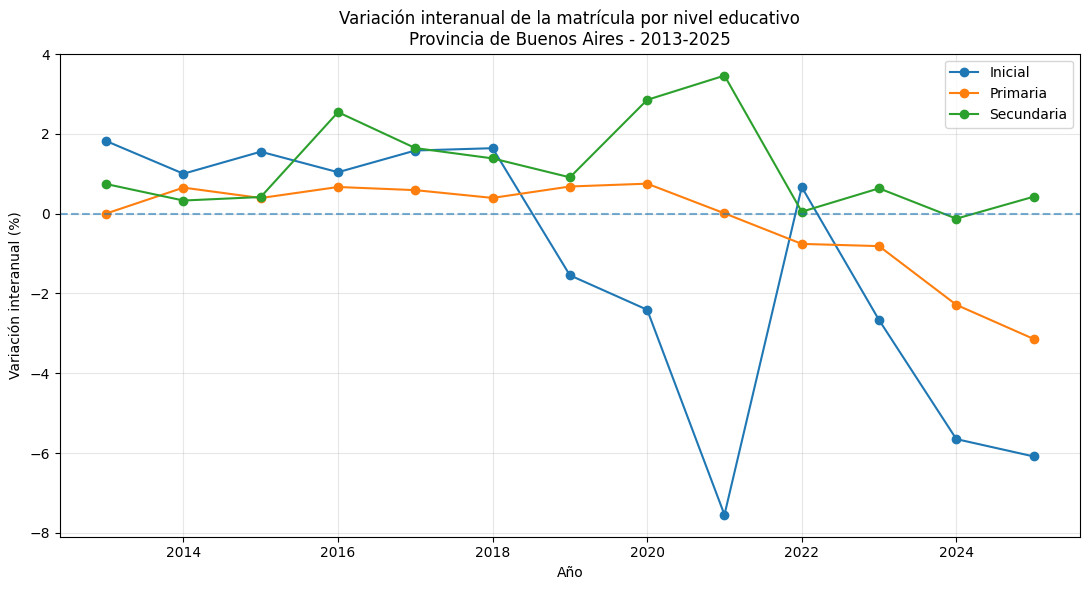

In [41]:
print("\n8.6 VARIACIÓN INTERANUAL DE LA MATRÍCULA POR NIVEL")

# Crear serie provincial anual
matricula_niveles_anual = (
    df[
        (df["anio"] >= 2012) &
        (df["anio"] <= 2025)
    ]
    .groupby("anio")[
        [
            "matricula_inicial",
            "matricula_primaria",
            "matricula_secundaria"
        ]
    ]
    .sum(min_count=1)
)

# Calcular variación porcentual respecto del año anterior
variacion_niveles = (
    matricula_niveles_anual
    .pct_change(fill_method=None) * 100
)

variacion_niveles.columns = [
    "variacion_inicial",
    "variacion_primaria",
    "variacion_secundaria"
]

print("\nVariación interanual de la matrícula por nivel (%):")

print(
    variacion_niveles
    .round(2)
    .to_string()
)

# IDENTIFICAR PRIMER AÑO CON VARIACIÓN NEGATIVA

print("\nPrimer año con variación negativa por nivel:")

for columna in variacion_niveles.columns:

    negativos = variacion_niveles[
        variacion_niveles[columna] < 0
    ]

    if not negativos.empty:

        primer_anio = negativos.index[0]
        valor = negativos.loc[primer_anio, columna]

        print(
            f"{columna}: {primer_anio} "
            f"({valor:.2f}%)"
        )

# GRÁFICO

plt.figure(figsize=(11, 6))

plt.plot(
    variacion_niveles.index,
    variacion_niveles["variacion_inicial"],
    marker="o",
    label="Inicial"
)

plt.plot(
    variacion_niveles.index,
    variacion_niveles["variacion_primaria"],
    marker="o",
    label="Primaria"
)

plt.plot(
    variacion_niveles.index,
    variacion_niveles["variacion_secundaria"],
    marker="o",
    label="Secundaria"
)

plt.axhline(
    y=0,
    linestyle="--",
    alpha=0.6
)

plt.xlabel("Año")
plt.ylabel("Variación interanual (%)")

plt.title(
    "Variación interanual de la matrícula por nivel educativo\n"
    "Provincia de Buenos Aires - 2013-2025"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Variación interanual de la matrícula por nivel educativo. El análisis muestra diferencias temporales claras entre los niveles. La matrícula de nivel Inicial registra su primera disminución en 2019 (-1,54%) y presenta una tendencia predominantemente descendente desde entonces. En Primaria, las variaciones negativas comienzan posteriormente, en 2022 (-0,76%), y se intensifican hasta alcanzar -3,14% en 2025. En cambio, la matrícula Secundaria mantiene variaciones mayormente positivas durante el período analizado, con una leve disminución en 2024 (-0,12%) y una nueva variación positiva en 2025 (+0,43%). Este comportamiento escalonado es consistente con la existencia de un desfase temporal en la manifestación de los cambios demográficos sobre los distintos niveles educativos, aunque no permite establecer por sí solo una relación causal.

## 8.7 SÍNTESIS DEL ANÁLISIS TEMPORAL

Síntesis del análisis temporal. El análisis de las series históricas evidencia cambios importantes en la dinámica demográfica y educativa de la Provincia de Buenos Aires. Entre 2012 y 2022, los nacimientos disminuyeron un 43,37%, mientras que la matrícula educativa presentó comportamientos diferentes según el nivel.

El nivel Inicial alcanzó su máximo en 2018 y comenzó a registrar variaciones interanuales negativas desde 2019. En Primaria, la disminución aparece posteriormente, con variaciones negativas desde 2022. En Secundaria, en cambio, la matrícula se mantuvo mayormente creciente durante el período analizado y alcanzó su valor máximo en 2025.

El análisis de rezagos temporales entre nacimientos y matrícula Inicial mostró asociaciones elevadas, especialmente para rezagos de 4 y 5 años (r = 0,975 y r = 0,976, respectivamente). En conjunto, estos resultados son consistentes con la existencia de un desfase temporal entre los cambios demográficos y su posterior manifestación en la demanda educativa.

Estos patrones resultan relevantes para el objetivo predictivo del proyecto, ya que indican que la evolución futura de la matrícula no debería analizarse únicamente a partir de sus valores contemporáneos, sino también considerando la evolución demográfica de años anteriores. Sin embargo, las asociaciones encontradas son de carácter exploratorio y no permiten establecer relaciones causales.

### 9. ANÁLISIS GEOGRÁFICO

### 9.1 Diferencias territoriales en la matrícula




9.1 DIFERENCIAS TERRITORIALES EN LA MATRÍCULA - 2025

Partidos con mayor matrícula total en 2025:
           partido  matricula_total
        LA MATANZA         355183.0
          LA PLATA         172363.0
   LOMAS DE ZAMORA         163623.0
            MORENO         144218.0
           QUILMES         139483.0
             MERLO         137578.0
GENERAL PUEYRREDON         136026.0
   ALMIRANTE BROWN         134125.0
  FLORENCIO VARELA         119427.0
             PILAR         109129.0

Partidos con menor matrícula total en 2025:
          partido  matricula_total
           LEZAMA            116.0
       PELLEGRINI            234.0
         TORDILLO            583.0
    GENERAL GUIDO            691.0
             PILA           1082.0
  GENERAL LAVALLE           1400.0
HIPOLITO YRIGOYEN           1452.0
     SAN CAYETANO           1471.0
         CASTELLI           1569.0
       SALLIQUELO           1711.0

Cantidad de partidos analizados:
135


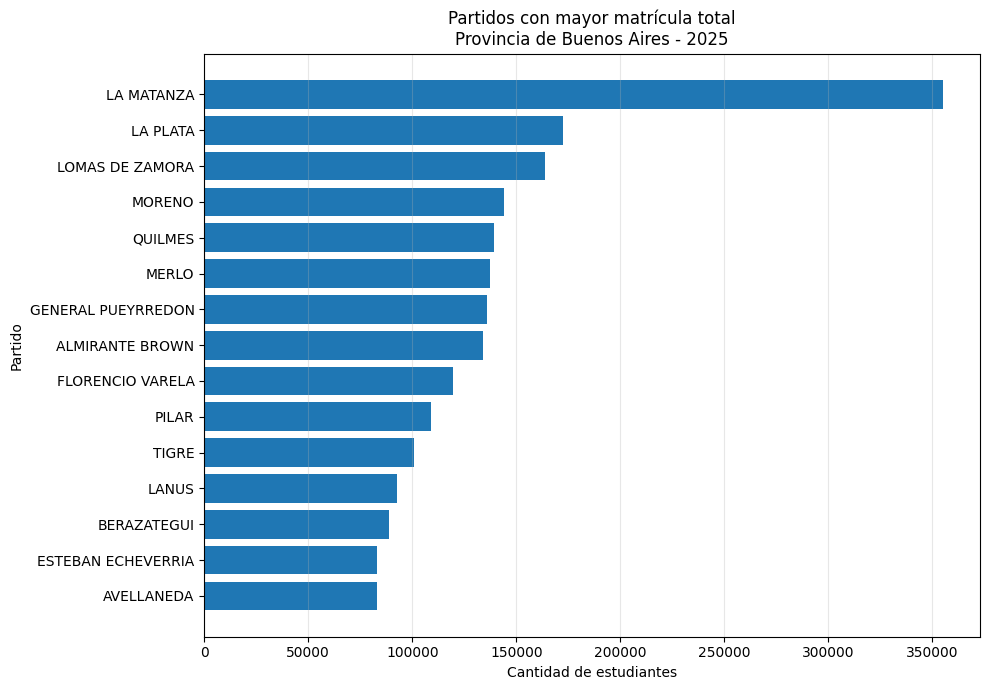

In [42]:
print("\n9.1 DIFERENCIAS TERRITORIALES EN LA MATRÍCULA - 2025")

datos_2025 = df[
    df["anio"] == 2025
][["partido", "matricula_total"]].copy()

datos_2025 = datos_2025.dropna(
    subset=["matricula_total"]
)

datos_2025 = datos_2025.sort_values(
    "matricula_total",
    ascending=False
)

print("\nPartidos con mayor matrícula total en 2025:")

print(
    datos_2025
    .head(10)
    .to_string(index=False)
)

print("\nPartidos con menor matrícula total en 2025:")

print(
    datos_2025
    .tail(10)
    .sort_values("matricula_total")
    .to_string(index=False)
)

print("\nCantidad de partidos analizados:")
print(len(datos_2025))


# Gráfico de los 15 partidos con mayor matrícula

top_15_matricula = datos_2025.head(15).sort_values(
    "matricula_total"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_15_matricula["partido"],
    top_15_matricula["matricula_total"]
)

plt.title(
    "Partidos con mayor matrícula total\n"
    "Provincia de Buenos Aires - 2025"
)

plt.xlabel("Cantidad de estudiantes")
plt.ylabel("Partido")

plt.grid(
    axis="x",
    alpha=0.3
)

plt.tight_layout()
plt.show()

Distribución territorial de la matrícula. En 2025 se observa una marcada heterogeneidad entre los partidos de la Provincia de Buenos Aires. La Matanza presenta la mayor matrícula total, con 355.183 estudiantes, seguida por La Plata (172.363) y Lomas de Zamora (163.623). También se registran valores elevados en Moreno, Quilmes, Merlo, General Pueyrredón y Almirante Brown. Estas diferencias son consistentes con las importantes variaciones de tamaño poblacional existentes entre los partidos y muestran que la demanda educativa no se distribuye de manera uniforme en el territorio provincial. Los valores extremadamente bajos de algunos partidos deben interpretarse con precaución debido a las diferencias de tamaño poblacional y, en casos previamente identificados como Lezama, a problemas de comparabilidad de los registros históricos.

### 9.2 CONCENTRACIÓN TERRITORIAL DE LA MATRÍCULA


In [43]:
print("\n9.2 CONCENTRACIÓN TERRITORIAL DE LA MATRÍCULA")

matricula_provincial_2025 = datos_2025["matricula_total"].sum()

print(
    f"\nMatrícula total provincial en 2025: "
    f"{matricula_provincial_2025:,.0f}"
)

# Calcular participación de cada partido
datos_2025["participacion_provincial"] = (
    datos_2025["matricula_total"]
    / matricula_provincial_2025
    * 100
)

datos_2025["participacion_acumulada"] = (
    datos_2025["participacion_provincial"].cumsum()
)

print("\nParticipación de los 10 partidos con mayor matrícula:")

print(
    datos_2025[
        [
            "partido",
            "matricula_total",
            "participacion_provincial",
            "participacion_acumulada"
        ]
    ]
    .head(10)
    .round(2)
    .to_string(index=False)
)

# Concentración en distintos grupos
for cantidad in [1, 5, 10, 20]:

    porcentaje = (
        datos_2025
        .head(cantidad)["matricula_total"]
        .sum()
        / matricula_provincial_2025
        * 100
    )

    print(
        f"\nLos {cantidad} partidos con mayor matrícula "
        f"concentran el {porcentaje:.2f}% "
        f"de la matrícula provincial."
    )


9.2 CONCENTRACIÓN TERRITORIAL DE LA MATRÍCULA

Matrícula total provincial en 2025: 3,849,256

Participación de los 10 partidos con mayor matrícula:
           partido  matricula_total  participacion_provincial  participacion_acumulada
        LA MATANZA         355183.0                      9.23                     9.23
          LA PLATA         172363.0                      4.48                    13.71
   LOMAS DE ZAMORA         163623.0                      4.25                    17.96
            MORENO         144218.0                      3.75                    21.70
           QUILMES         139483.0                      3.62                    25.33
             MERLO         137578.0                      3.57                    28.90
GENERAL PUEYRREDON         136026.0                      3.53                    32.43
   ALMIRANTE BROWN         134125.0                      3.48                    35.92
  FLORENCIO VARELA         119427.0                      3.10       

Concentración territorial de la matrícula. En 2025, la matrícula total de la Provincia de Buenos Aires alcanzó los 3.849.256 estudiantes y presentó una importante concentración territorial. La Matanza representó por sí sola el 9,23% de la matrícula provincial. Los cinco partidos con mayor cantidad de estudiantes concentraron el 25,33%, mientras que los diez primeros reunieron el 41,86%. Al considerar los veinte partidos con mayor matrícula, la participación acumulada alcanzó el 63,63%. Estos resultados muestran que la demanda educativa se distribuye de manera heterogénea entre los 135 partidos y refuerzan la importancia de realizar estimaciones desagregadas territorialmente, evitando que los valores provinciales agregados oculten las diferencias existentes entre partidos.

###10. Primeros hallazgos

El análisis exploratorio permitió identificar los siguientes hallazgos principales:

1. Existe una fuerte heterogeneidad entre los partidos.
La matrícula educativa presenta diferencias muy importantes entre los 135 partidos de la Provincia de Buenos Aires. En 2025, por ejemplo, La Matanza registró 355.183 estudiantes, mientras que otros partidos presentaron valores considerablemente menores. Además, los 20 partidos con mayor matrícula concentraron el 63,63% de la matrícula provincial. Esto muestra la importancia de analizar y posteriormente estimar la demanda educativa a nivel de partido, en lugar de utilizar únicamente valores provinciales agregados.

2. Los nacimientos muestran una marcada tendencia descendente.
Entre 2012 y 2022, los nacimientos registrados disminuyeron un 43,37%. Esta caída constituye uno de los principales cambios demográficos observados durante el período analizado y puede resultar relevante para comprender la evolución futura de la población en edades educativas.

3. La evolución de la matrícula es diferente según el nivel educativo.
Entre 2012 y 2025, la matrícula de nivel Inicial disminuyó un 15,96% y la de Primaria un 2,89%, mientras que la matrícula de Secundaria aumentó un 16,32%. Por lo tanto, la evolución de la demanda educativa no es uniforme entre los distintos niveles.

4. La disminución de la matrícula aparece en diferentes momentos según el nivel.
El nivel Inicial comenzó a presentar variaciones interanuales negativas desde 2019, mientras que en Primaria este comportamiento aparece posteriormente, desde 2022. Secundaria, en cambio, mantuvo una evolución mayormente creciente durante el período analizado. Este comportamiento escalonado es consistente con el desplazamiento de las cohortes a través de los distintos niveles educativos.

5. Se identificó un posible desfase temporal entre nacimientos y matrícula.
El análisis temporal mostró asociaciones elevadas entre los nacimientos y la matrícula de nivel Inicial algunos años después. Las mayores correlaciones se observaron con rezagos de cuatro años (r = 0,975) y cinco años (r = 0,976). Este resultado sugiere que las variables demográficas de años anteriores pueden aportar información relevante para la posterior etapa predictiva. Sin embargo, debido a la cantidad limitada de observaciones temporales, estas asociaciones deben interpretarse de manera exploratoria y no causal.

6. Las variables demográficas presentan una fuerte asociación con el volumen de matrícula.
Variables como nacimientos, población total y población correspondiente a distintos grupos etarios mostraron correlaciones elevadas con la matrícula total. Parte importante de estas asociaciones está relacionada con el tamaño de los partidos: los partidos con mayor población también tienden a presentar una mayor cantidad de estudiantes.

7. También se observaron asociaciones con variables socioeconómicas y habitacionales.
Las tasas de actividad, empleo y desocupación, junto con indicadores como acceso a agua de red, cloacas y disponibilidad de baño, mostraron distintos grados de asociación con las variables educativas. Estas relaciones son descriptivas y pueden estar influenciadas por las características demográficas y territoriales de cada partido, por lo que no deben interpretarse como relaciones causales.

8. Los resultados respaldan un enfoque predictivo desagregado territorialmente y por nivel educativo.
Las diferencias encontradas entre partidos, niveles educativos y períodos muestran que una única tendencia provincial no representa adecuadamente toda la realidad educativa bonaerense. Por este motivo, la etapa de modelado deberá considerar la dimensión territorial y las diferencias entre Inicial, Primaria y Secundaria, incorporando tanto la evolución histórica de la matrícula como la información demográfica disponible.

###11. Revisión de la pregunta y del alcance

A partir de los resultados obtenidos durante el análisis exploratorio, se considera que la pregunta de datos planteada inicialmente continúa siendo adecuada:

¿Cómo evolucionará la demanda educativa, medida a través de la matrícula, en los distintos partidos de la Provincia de Buenos Aires hasta 2035, y qué factores demográficos, educativos, socioeconómicos y habitacionales se relacionan con su evolución?

El análisis realizado mostró diferencias importantes en la evolución de la matrícula entre partidos y niveles educativos, así como asociaciones con variables demográficas, socioeconómicas y habitacionales. Además, se identificaron posibles desfases temporales entre la evolución de los nacimientos y la matrícula, lo que respalda la incorporación de información histórica y demográfica en la etapa de modelado.

Por lo tanto, se mantiene el alcance territorial en los 135 partidos de la Provincia de Buenos Aires, considerando los niveles Inicial, Primario y Secundario, con información histórica disponible principalmente entre 2012 y 2025 y un horizonte de estimación hasta 2035.

Los resultados del EDA también indican que las futuras estimaciones deberían realizarse de manera desagregada por partido y nivel educativo, evitando utilizar únicamente una tendencia provincial general.

### 12. DICCIONARIO DE DATOS



In [44]:
print("12. DICCIONARIO DE DATOS")

# Primero verificamos las variables reales del dataset
print(f"\nCantidad total de variables: {df.shape[1]}")

for i, columna in enumerate(df.columns, start=1):
    print(f"{i}. {columna} ({df[columna].dtype})")

12. DICCIONARIO DE DATOS

Cantidad total de variables: 62
1. partido (object)
2. anio (int64)
3. nacimientos (float64)
4. poblacion_total (float64)
5. tbn (float64)
6. matricula_inicial (float64)
7. matricula_primaria (float64)
8. matricula_secundaria (float64)
9. matricula_total (float64)
10. poblacion_estimada (float64)
11. poblacion_educacion_censo (float64)
12. asiste_censo_2022 (float64)
13. no_asiste_pero_asistio_censo_2022 (float64)
14. nunca_asistio_censo_2022 (float64)
15. tasa_asistencia_censo_2022 (float64)
16. porcentaje_nunca_asistio_censo_2022 (float64)
17. asiste_jardin_0_3_censo_2022 (float64)
18. asiste_sala_4_5_censo_2022 (float64)
19. asiste_primario_censo_2022 (float64)
20. asiste_secundario_censo_2022 (float64)
21. asiste_terciario_censo_2022 (float64)
22. asiste_universitario_censo_2022 (float64)
23. asiste_posgrado_censo_2022 (float64)
24. mujeres_14_49_censo_2022 (float64)
25. mujeres_sin_hijos_censo_2022 (float64)
26. mujeres_con_1_hijo_censo_2022 (float64)
27.

### 12.1 CONSTRUCCIÓN DEL DICCIONARIO DE DATOS


In [45]:
descripciones = {
    "partido": "Partido de la Provincia de Buenos Aires.",
    "anio": "Año de referencia del registro.",

    "nacimientos": "Cantidad de nacimientos registrados en el partido y año.",
    "poblacion_total": "Población total del partido.",
    "tbn": "Tasa bruta de natalidad.",

    "matricula_inicial": "Cantidad de estudiantes matriculados en el nivel Inicial.",
    "matricula_primaria": "Cantidad de estudiantes matriculados en el nivel Primario.",
    "matricula_secundaria": "Cantidad de estudiantes matriculados en el nivel Secundario.",
    "matricula_total": "Matrícula total de los niveles Inicial, Primario y Secundario.",

    "poblacion_estimada": "Población estimada del partido para el año correspondiente.",

    "poblacion_educacion_censo": "Población considerada en las variables educativas del Censo 2022.",
    "asiste_censo_2022": "Población que asiste a un establecimiento educativo según el Censo 2022.",
    "no_asiste_pero_asistio_censo_2022": "Población que no asiste actualmente pero asistió a un establecimiento educativo.",
    "nunca_asistio_censo_2022": "Población que nunca asistió a un establecimiento educativo.",
    "tasa_asistencia_censo_2022": "Porcentaje de la población considerada que asiste a un establecimiento educativo.",
    "porcentaje_nunca_asistio_censo_2022": "Porcentaje de la población considerada que nunca asistió a un establecimiento educativo.",

    "asiste_jardin_0_3_censo_2022": "Población que asiste a jardín maternal o nivel equivalente de 0 a 3 años.",
    "asiste_sala_4_5_censo_2022": "Población que asiste a salas de 4 y 5 años.",
    "asiste_primario_censo_2022": "Población que asiste al nivel Primario.",
    "asiste_secundario_censo_2022": "Población que asiste al nivel Secundario.",
    "asiste_terciario_censo_2022": "Población que asiste al nivel Terciario.",
    "asiste_universitario_censo_2022": "Población que asiste al nivel Universitario.",
    "asiste_posgrado_censo_2022": "Población que asiste a estudios de Posgrado.",

    "mujeres_14_49_censo_2022": "Cantidad de mujeres de 14 a 49 años según el Censo 2022.",
    "mujeres_sin_hijos_censo_2022": "Mujeres de 14 a 49 años sin hijos.",
    "mujeres_con_1_hijo_censo_2022": "Mujeres de 14 a 49 años con un hijo.",
    "mujeres_con_2_hijos_censo_2022": "Mujeres de 14 a 49 años con dos hijos.",
    "mujeres_con_3_hijos_censo_2022": "Mujeres de 14 a 49 años con tres hijos.",
    "mujeres_con_4_hijos_censo_2022": "Mujeres de 14 a 49 años con cuatro hijos.",
    "mujeres_con_5_mas_hijos_censo_2022": "Mujeres de 14 a 49 años con cinco hijos o más.",
    "promedio_hijos_por_mujer_censo_2022": "Promedio de hijos por mujer de 14 a 49 años según el Censo 2022.",

    "poblacion_14_mas": "Población de 14 años o más.",
    "pea": "Población económicamente activa.",
    "ocupados": "Cantidad de personas ocupadas.",
    "desocupados": "Cantidad de personas desocupadas.",
    "poblacion_no_economicamente_activa": "Población no económicamente activa.",
    "tasa_actividad": "Porcentaje de población económicamente activa.",
    "tasa_empleo": "Porcentaje de población ocupada.",
    "tasa_desocupacion": "Porcentaje de población económicamente activa que se encuentra desocupada.",

    "hogares_total": "Cantidad total de hogares.",
    "hogares_agua_red": "Cantidad de hogares con acceso a agua de red.",
    "porcentaje_hogares_agua_red": "Porcentaje de hogares con acceso a agua de red.",
    "hogares_con_cloaca": "Cantidad de hogares con acceso a desagüe cloacal.",
    "porcentaje_hogares_cloaca": "Porcentaje de hogares con acceso a desagüe cloacal.",
    "hogares_sin_banio": "Cantidad de hogares sin baño.",
    "porcentaje_hogares_sin_banio": "Porcentaje de hogares sin baño.",

    "poblacion_5_mas": "Población de 5 años o más considerada para el análisis de residencia previa.",
    "residencia_2017_misma_localidad": "Población que en 2017 residía en la misma localidad.",
    "residencia_2017_otra_localidad_pba": "Población que en 2017 residía en otra localidad de la Provincia de Buenos Aires.",
    "residencia_2017_otra_provincia": "Población que en 2017 residía en otra provincia.",
    "residencia_2017_otro_pais": "Población que en 2017 residía en otro país.",
    "poblacion_residia_fuera_localidad_2017": "Población que en 2017 residía fuera de la localidad actual.",
    "porcentaje_residia_fuera_localidad_2017": "Porcentaje de población que en 2017 residía fuera de la localidad actual.",

    "poblacion_2010": "Población registrada en el Censo 2010.",
    "poblacion_2022": "Población registrada en el Censo 2022.",
    "variacion_absoluta": "Variación absoluta de población entre los censos 2010 y 2022.",
    "variacion_relativa": "Variación porcentual de población entre los censos 2010 y 2022.",

    "superficie_km2": "Superficie del partido expresada en kilómetros cuadrados.",
    "densidad_2022": "Densidad poblacional en 2022, expresada en habitantes por kilómetro cuadrado.",

    "poblacion_0_5": "Población de 0 a 5 años.",
    "poblacion_6_11": "Población de 6 a 11 años.",
    "poblacion_12_17": "Población de 12 a 17 años."
}


# Dimensión temática de cada variable
def obtener_dimension(variable):

    if variable in ["partido", "anio"]:
        return "Identificación"

    elif variable in [
        "matricula_inicial",
        "matricula_primaria",
        "matricula_secundaria",
        "matricula_total",
        "poblacion_educacion_censo",
        "asiste_censo_2022",
        "no_asiste_pero_asistio_censo_2022",
        "nunca_asistio_censo_2022",
        "tasa_asistencia_censo_2022",
        "porcentaje_nunca_asistio_censo_2022",
        "asiste_jardin_0_3_censo_2022",
        "asiste_sala_4_5_censo_2022",
        "asiste_primario_censo_2022",
        "asiste_secundario_censo_2022",
        "asiste_terciario_censo_2022",
        "asiste_universitario_censo_2022",
        "asiste_posgrado_censo_2022"
    ]:
        return "Educativa"

    elif variable in [
        "nacimientos",
        "tbn",
        "mujeres_14_49_censo_2022",
        "mujeres_sin_hijos_censo_2022",
        "mujeres_con_1_hijo_censo_2022",
        "mujeres_con_2_hijos_censo_2022",
        "mujeres_con_3_hijos_censo_2022",
        "mujeres_con_4_hijos_censo_2022",
        "mujeres_con_5_mas_hijos_censo_2022",
        "promedio_hijos_por_mujer_censo_2022"
    ]:
        return "Natalidad y fecundidad"

    elif variable in [
        "poblacion_total",
        "poblacion_estimada",
        "poblacion_2010",
        "poblacion_2022",
        "variacion_absoluta",
        "variacion_relativa",
        "superficie_km2",
        "densidad_2022",
        "poblacion_0_5",
        "poblacion_6_11",
        "poblacion_12_17"
    ]:
        return "Demográfica"

    elif variable in [
        "poblacion_14_mas",
        "pea",
        "ocupados",
        "desocupados",
        "poblacion_no_economicamente_activa",
        "tasa_actividad",
        "tasa_empleo",
        "tasa_desocupacion"
    ]:
        return "Socioeconómica"

    elif variable in [
        "hogares_total",
        "hogares_agua_red",
        "porcentaje_hogares_agua_red",
        "hogares_con_cloaca",
        "porcentaje_hogares_cloaca",
        "hogares_sin_banio",
        "porcentaje_hogares_sin_banio"
    ]:
        return "Habitacional"

    elif variable in [
        "poblacion_5_mas",
        "residencia_2017_misma_localidad",
        "residencia_2017_otra_localidad_pba",
        "residencia_2017_otra_provincia",
        "residencia_2017_otro_pais",
        "poblacion_residia_fuera_localidad_2017",
        "porcentaje_residia_fuera_localidad_2017"
    ]:
        return "Migratoria"

    return "Otra"


# Crear diccionario automáticamente a partir de las columnas reales
diccionario_datos = pd.DataFrame({
    "variable": df.columns,
    "tipo_dato": [str(df[col].dtype) for col in df.columns],
    "dimension": [obtener_dimension(col) for col in df.columns],
    "descripcion": [
        descripciones.get(col, "Descripción pendiente")
        for col in df.columns
    ]
})

print(f"\nVariables documentadas: {len(diccionario_datos)}")

display(diccionario_datos)


Variables documentadas: 62


,variable,tipo_dato,dimension,descripcion
0,partido,object,Identificación,Partido de la Provincia de Buenos Aires.
1,anio,int64,Identificación,Año de referencia del registro.
2,nacimientos,float64,Natalidad y fecundidad,Cantidad de nacimientos registrados en el part...
3,poblacion_total,float64,Demográfica,Población total del partido.
4,tbn,float64,Natalidad y fecundidad,Tasa bruta de natalidad.
...,...,...,...,...
57,superficie_km2,float64,Demográfica,Superficie del partido expresada en kilómetros...
58,densidad_2022,float64,Demográfica,"Densidad poblacional en 2022, expresada en hab..."
59,poblacion_0_5,float64,Demográfica,Población de 0 a 5 años.
60,poblacion_6_11,float64,Demográfica,Población de 6 a 11 años.


### 12.2 FUENTE Y COBERTURA TEMPORAL




In [49]:
def obtener_fuente(variable):

    # Identificación
    if variable in ["partido", "anio"]:
        return "Dataset maestro integrado"

    # Matrícula
    elif variable in [
        "matricula_inicial",
        "matricula_primaria",
        "matricula_secundaria",
        "matricula_total"
    ]:
        return "Relevamiento Anual educativo"

    # Nacimientos
    elif variable == "nacimientos":
        return "RENAPER"

    # Población histórica / natalidad
    elif variable in [
        "poblacion_total",
        "tbn"
    ]:
        return "Estadísticas demográficas oficiales"

    # Estimaciones futuras de población
    elif variable == "poblacion_estimada":
        return "INDEC - Estimaciones de población"

    # Variables censales
    elif variable in [
        "poblacion_educacion_censo",
        "asiste_censo_2022",
        "no_asiste_pero_asistio_censo_2022",
        "nunca_asistio_censo_2022",
        "tasa_asistencia_censo_2022",
        "porcentaje_nunca_asistio_censo_2022",
        "asiste_jardin_0_3_censo_2022",
        "asiste_sala_4_5_censo_2022",
        "asiste_primario_censo_2022",
        "asiste_secundario_censo_2022",
        "asiste_terciario_censo_2022",
        "asiste_universitario_censo_2022",
        "asiste_posgrado_censo_2022",
        "mujeres_14_49_censo_2022",
        "mujeres_sin_hijos_censo_2022",
        "mujeres_con_1_hijo_censo_2022",
        "mujeres_con_2_hijos_censo_2022",
        "mujeres_con_3_hijos_censo_2022",
        "mujeres_con_4_hijos_censo_2022",
        "mujeres_con_5_mas_hijos_censo_2022",
        "promedio_hijos_por_mujer_censo_2022",
        "poblacion_14_mas",
        "pea",
        "ocupados",
        "desocupados",
        "poblacion_no_economicamente_activa",
        "tasa_actividad",
        "tasa_empleo",
        "tasa_desocupacion",
        "hogares_total",
        "hogares_agua_red",
        "porcentaje_hogares_agua_red",
        "hogares_con_cloaca",
        "porcentaje_hogares_cloaca",
        "hogares_sin_banio",
        "porcentaje_hogares_sin_banio",
        "poblacion_5_mas",
        "residencia_2017_misma_localidad",
        "residencia_2017_otra_localidad_pba",
        "residencia_2017_otra_provincia",
        "residencia_2017_otro_pais",
        "poblacion_residia_fuera_localidad_2017",
        "porcentaje_residia_fuera_localidad_2017",
        "poblacion_2022",
        "superficie_km2",
        "densidad_2022",
        "poblacion_0_5",
        "poblacion_6_11",
        "poblacion_12_17"
    ]:
        return "INDEC - Censo Nacional 2022"

    # Comparación intercensal
    elif variable in [
        "poblacion_2010",
        "variacion_absoluta",
        "variacion_relativa"
    ]:
        return "INDEC - Censos 2010 y 2022"

    return "Revisar fuente"


def obtener_cobertura(variable):

    # Variables de identificación
    if variable in ["partido", "anio"]:
        return "2012-2035"

    # Matrícula
    elif variable in [
        "matricula_inicial",
        "matricula_primaria",
        "matricula_secundaria",
        "matricula_total"
    ]:
        return "2012-2025"

    # Nacimientos
    elif variable == "nacimientos":
        return "2012-2022"

    # Población histórica y TBN
    elif variable in [
        "poblacion_total",
        "tbn"
    ]:
        return "2012-2022"

    # Estimaciones de población
    elif variable == "poblacion_estimada":
        return "2022-2035"

    # Población del Censo 2010
    elif variable == "poblacion_2010":
        return "2010"

    # Variables que comparan los censos 2010 y 2022
    elif variable in [
        "variacion_absoluta",
        "variacion_relativa"
    ]:
        return "2010 y 2022"

    # Las demás variables corresponden al Censo 2022
    else:
        return "2022"


# Agregar las columnas al diccionario
diccionario_datos["fuente"] = [
    obtener_fuente(variable)
    for variable in diccionario_datos["variable"]
]

diccionario_datos["cobertura_temporal"] = [
    obtener_cobertura(variable)
    for variable in diccionario_datos["variable"]
]


# Reordenar las columnas para que quede más claro
diccionario_datos = diccionario_datos[
    [
        "variable",
        "tipo_dato",
        "dimension",
        "descripcion",
        "fuente",
        "cobertura_temporal"
    ]
]


# Controles
print("12.2 FUENTE Y COBERTURA TEMPORAL")

print(
    f"\nVariables documentadas: "
    f"{len(diccionario_datos)}"
)

print(
    f"Variables con fuente pendiente: "
    f"{(diccionario_datos['fuente'] == 'Revisar fuente').sum()}"
)

display(diccionario_datos)

12.2 FUENTE Y COBERTURA TEMPORAL

Variables documentadas: 62
Variables con fuente pendiente: 0


,variable,tipo_dato,dimension,descripcion,fuente,cobertura_temporal
0,partido,object,Identificación,Partido de la Provincia de Buenos Aires.,Dataset maestro integrado,2012-2035
1,anio,int64,Identificación,Año de referencia del registro.,Dataset maestro integrado,2012-2035
2,nacimientos,float64,Natalidad y fecundidad,Cantidad de nacimientos registrados en el part...,RENAPER,2012-2022
3,poblacion_total,float64,Demográfica,Población total del partido.,Estadísticas demográficas oficiales,2012-2022
4,tbn,float64,Natalidad y fecundidad,Tasa bruta de natalidad.,Estadísticas demográficas oficiales,2012-2022
...,...,...,...,...,...,...
57,superficie_km2,float64,Demográfica,Superficie del partido expresada en kilómetros...,INDEC - Censo Nacional 2022,2022
58,densidad_2022,float64,Demográfica,"Densidad poblacional en 2022, expresada en hab...",INDEC - Censo Nacional 2022,2022
59,poblacion_0_5,float64,Demográfica,Población de 0 a 5 años.,INDEC - Censo Nacional 2022,2022
60,poblacion_6_11,float64,Demográfica,Población de 6 a 11 años.,INDEC - Censo Nacional 2022,2022
